> **Reference run, executed on Kaggle (Tesla T4) on 2026-11-09, with all outputs.**  
> Original: https://www.kaggle.com/code/lalithtrs/yolo-trt-kaggle  
> Changes in this copy: only the PyTorch baseline cell's output was shortened, where 7,170 identical Ultralytics `half is deprecated` warning lines are collapsed into a single marker line. Nothing else was edited.  
> Notes for readers: the Step 10 table was generated before the INT8 MinMax and GPU clock cells were run (see the execution numbers) and with an earlier version of `make_results.py`; the final tables, including MinMax, are in `results/results.md` and the README. To re-run, use `notebooks/yolo_trt_kaggle.ipynb` (latest code: version pins, warning fix, and the MinMax / clock steps built in).

# YOLOv8s → TensorRT C++ pipeline: full run on Kaggle

This notebook does the whole project end to end and prints every result:

1. checks the GPU, installs TensorRT / Ultralytics / OpenCV, **builds the C++ app and runs a TensorRT smoke test first**
2. gets COCO val2017, exports YOLOv8s to ONNX, builds **FP32 / FP16 / INT8** TensorRT engines
3. measures the **PyTorch baseline** (latency + mAP)
4. measures the **C++ TensorRT pipeline** per stage (P50 / P95), baseline vs optimised CPU path, and **COCO mAP**
5. writes a results table, correctness checks, a latency chart and a demo GIF

### How to run
1. **Settings → Accelerator → GPU T4** (T4 ×2 is fine, GPU 0 is used). Not P100: Pascal has no fast FP16/INT8.
2. **Settings → Internet → On** (needs a phone-verified Kaggle account).
3. Optional: **Add Input → search "COCO 2017"** and attach a dataset with `val2017/` + `instances_val2017.json` to skip the ~1 GB download. Otherwise it is downloaded automatically.
4. **Run All.** Full run takes roughly 1–1.5 h. Set `QUICK = True` below for a ~20 min smoke run on fewer images.

The run stops at the first failing step, with the error printed under that cell.
All results land in `/kaggle/working/yolo-tensorrt-cpp/results/` and in `yolo-tensorrt-cpp-results.zip` (Output panel).

In [1]:
import os, json, subprocess, sys

QUICK = False                      # True = fast smoke run (fewer images, 1 benchmark repeat)
REPO = '/kaggle/working/yolo-tensorrt-cpp'
N_EVAL = 500 if QUICK else 4500    # images scored for mAP (first N of val2017)
N_CALIB = 200 if QUICK else 500    # INT8 calibration images (last N of val2017, never scored)
REPEATS = 1 if QUICK else 3        # benchmark repeats (median is reported)
ITERS = 200 if QUICK else 500      # timed frames per benchmark (after 50 warm-up frames)

os.environ['CUDA_VISIBLE_DEVICES'] = '0'   # same single GPU for every measurement
for d in ['src', 'scripts', 'results', 'data', 'models', 'engines']:
    os.makedirs(f'{REPO}/{d}', exist_ok=True)

def sh(cmd):
    """Run a shell command in the repo, stream its output, stop the notebook if it fails."""
    print('$', cmd, flush=True)
    p = subprocess.Popen(cmd, shell=True, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end='', flush=True)
    if p.wait() != 0:
        raise RuntimeError(f'command failed (exit {p.returncode}): {cmd}')

gpu = subprocess.run('nvidia-smi --query-gpu=name --format=csv,noheader -i 0', shell=True,
                     capture_output=True, text=True).stdout.strip()
print('GPU 0:', gpu or 'NONE')
assert gpu, 'No GPU. Settings > Accelerator > GPU T4, then restart the session.'
if 'T4' not in gpu:
    print('WARNING: this project assumes a T4; numbers on other GPUs are not comparable.')

GPU 0: Tesla T4


## Step 1: Project source files
Every file of the repo is written here, so the notebook needs nothing but Internet access.
(Generated from the repo by `tools/make_notebook.py`; the code is identical to the GitHub version.)

In [2]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/CMakeLists.txt
cmake_minimum_required(VERSION 3.18)
project(yolo_trt LANGUAGES CXX)

set(CMAKE_CXX_STANDARD 17)
set(CMAKE_CXX_STANDARD_REQUIRED ON)
if(NOT CMAKE_BUILD_TYPE)
  set(CMAKE_BUILD_TYPE Release)
endif()

# Paths are passed in by scripts/setup_cpp.py (it finds them on the machine):
#   TRT_INC    folder with NvInfer.h            TRT_LIB     full path to libnvinfer.so.<major>
#   CUDA_INC   folder with cuda_runtime_api.h   CUDART_LIB  full path to libcudart.so[.<major>]
foreach(v TRT_INC TRT_LIB CUDA_INC CUDART_LIB)
  if(NOT DEFINED ${v})
    message(FATAL_ERROR "Pass -D${v}=... (run scripts/setup_cpp.py instead of calling cmake directly)")
  endif()
endforeach()

get_filename_component(TRT_LIB_DIR ${TRT_LIB} DIRECTORY)
get_filename_component(CUDART_DIR ${CUDART_LIB} DIRECTORY)
# Bake the library folders into the binaries so no LD_LIBRARY_PATH is needed. The C++ app then
# loads the very same libnvinfer that built the engines in Python, so versions always match.
set(CMAKE_BUILD_RPATH "${TRT_LIB_DIR};${CUDART_DIR}")

add_executable(hello_trt src/hello_trt.cpp)

find_package(OpenCV REQUIRED COMPONENTS core imgproc imgcodecs videoio)
add_executable(yolo_trt src/main.cpp)
target_include_directories(yolo_trt PRIVATE ${OpenCV_INCLUDE_DIRS})
target_link_libraries(yolo_trt PRIVATE ${OpenCV_LIBS})
target_compile_options(yolo_trt PRIVATE -O3 -march=native)

foreach(t hello_trt yolo_trt)
  target_include_directories(${t} PRIVATE ${TRT_INC} ${CUDA_INC})
  target_link_libraries(${t} PRIVATE ${TRT_LIB} ${CUDART_LIB})
  target_compile_options(${t} PRIVATE -Wall -Wno-deprecated-declarations)
endforeach()

Writing /kaggle/working/yolo-tensorrt-cpp/CMakeLists.txt


In [3]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/src/hello_trt.cpp
// Day-1 toolchain smoke test: if this compiles, links and prints "OK", the C++/TensorRT/CUDA
// setup is correct and the rest of the project is ordinary code.
#include <NvInfer.h>
#include <cuda_runtime_api.h>

#include <iostream>

struct Logger : nvinfer1::ILogger {
  void log(Severity s, const char* m) noexcept override {
    if (s <= Severity::kWARNING) std::cerr << "[TRT] " << m << std::endl;
  }
} gLog;

int main() {
  int rtv = 0, drv = 0;
  cudaRuntimeGetVersion(&rtv);
  cudaDriverGetVersion(&drv);
  cudaDeviceProp p{};
  if (cudaGetDeviceProperties(&p, 0) != cudaSuccess) {
    std::cerr << "FAIL: no CUDA device visible" << std::endl;
    return 1;
  }
  std::cout << "GPU            : " << p.name << " (sm_" << p.major << p.minor << ")\n"
            << "CUDA runtime   : " << rtv << ", driver supports " << drv << "\n"
#ifdef NV_TENSORRT_MAJOR
            << "TensorRT header: " << NV_TENSORRT_MAJOR << "." << NV_TENSORRT_MINOR << "." << NV_TENSORRT_PATCH << "\n"
#endif
            << "TensorRT lib   : " << getInferLibVersion() << std::endl;
  nvinfer1::IRuntime* rt = nvinfer1::createInferRuntime(gLog);
  if (!rt) {
    std::cerr << "FAIL: createInferRuntime returned null (header/library version mismatch?)" << std::endl;
    return 1;
  }
  delete rt;
  std::cout << "OK: TensorRT runtime created from C++" << std::endl;
  return 0;
}

Writing /kaggle/working/yolo-tensorrt-cpp/src/hello_trt.cpp


In [4]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/src/main.cpp
// yolo_trt: YOLOv8 inference with TensorRT in C++.
//
//   yolo_trt ENGINE bench LIST            [--fast] [--iters N] [--warmup N]
//   yolo_trt ENGINE coco  LIST OUT.csv    [--fast]
//   yolo_trt ENGINE video IN.mp4 OUT.mp4  [--fast]
//
// Two CPU code paths, selected with --fast:
//   baseline : OpenCV letterbox + cvtColor + convertTo + split; anchor-major decode (strided reads)
//   --fast   : one fused pass (resize -> RGB/255/CHW + padding, LUT);  class-major decode (contiguous,
//              vectorisable reads). Both paths give the same detections (checked by run_trt.py).
#include <NvInfer.h>
#include <cuda_runtime_api.h>
#include <opencv2/core.hpp>
#include <opencv2/imgcodecs.hpp>
#include <opencv2/imgproc.hpp>
#include <opencv2/videoio.hpp>

#include <algorithm>
#include <chrono>
#include <cmath>
#include <cstdint>
#include <cstdlib>
#include <fstream>
#include <iomanip>
#include <iostream>
#include <iterator>
#include <memory>
#include <string>
#include <vector>

#define CK(x)                                                                                   \
  do {                                                                                          \
    cudaError_t e_ = (x);                                                                       \
    if (e_ != cudaSuccess) {                                                                    \
      std::cerr << "CUDA error: " << cudaGetErrorString(e_) << " at line " << __LINE__ << "\n"; \
      std::exit(1);                                                                             \
    }                                                                                           \
  } while (0)

[[noreturn]] static void die(const std::string& m) { std::cerr << "ERROR: " << m << std::endl; std::exit(1); }

struct Logger : nvinfer1::ILogger {
  void log(Severity s, const char* m) noexcept override {
    if (s <= Severity::kWARNING) std::cerr << "[TRT] " << m << std::endl;
  }
} gLog;

static const int COCO91[80] = {1,  2,  3,  4,  5,  6,  7,  8,  9,  10, 11, 13, 14, 15, 16, 17, 18, 19, 20, 21,
                               22, 23, 24, 25, 27, 28, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44,
                               46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65,
                               67, 70, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 84, 85, 86, 87, 88, 89, 90};

static const char* NAMES[80] = {
    "person", "bicycle", "car", "motorcycle", "airplane", "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench", "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack", "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite", "baseball bat", "baseball glove", "skateboard", "surfboard",
    "tennis racket", "bottle", "wine glass", "cup", "fork", "knife", "spoon", "bowl", "banana", "apple",
    "sandwich", "orange", "broccoli", "carrot", "hot dog", "pizza", "donut", "cake", "chair", "couch",
    "potted plant", "bed", "dining table", "toilet", "tv", "laptop", "mouse", "remote", "keyboard",
    "cell phone", "microwave", "oven", "toaster", "sink", "refrigerator", "book", "clock", "vase",
    "scissors", "teddy bear", "hair drier", "toothbrush"};

struct Det { float x1, y1, x2, y2, score; int cls; };
struct LB { float scale; int px, py, nw, nh; };
struct GpuTimes { float h2d, infer, d2h, total; };

// ---------------------------------------------------------------------------------------------
// TensorRT engine wrapper: one static [1,3,S,S] float input, one [1,C,N] float output.
// Pinned host buffers + one CUDA stream; CUDA events time each GPU stage.
// ---------------------------------------------------------------------------------------------
struct Trt {
  std::unique_ptr<nvinfer1::IRuntime> rt;
  std::unique_ptr<nvinfer1::ICudaEngine> eng;
  std::unique_ptr<nvinfer1::IExecutionContext> ctx;
  int S = 640, C = 84, N = 8400;
  size_t inBytes = 0, outBytes = 0;
  float *dIn = nullptr, *dOut = nullptr, *hIn = nullptr, *hOut = nullptr;
  cudaStream_t st = nullptr;
  cudaEvent_t ev[4] = {};
  std::string inName, outName;

  explicit Trt(const std::string& path) {
    std::ifstream f(path, std::ios::binary);
    if (!f) die("cannot open engine " + path);
    std::vector<char> buf((std::istreambuf_iterator<char>(f)), std::istreambuf_iterator<char>());
    rt.reset(nvinfer1::createInferRuntime(gLog));
    if (!rt) die("createInferRuntime failed");
    eng.reset(rt->deserializeCudaEngine(buf.data(), buf.size()));
    if (!eng) die("engine load failed (built with another TensorRT version or GPU? rebuild it in this session)");
    ctx.reset(eng->createExecutionContext());
    if (!ctx) die("createExecutionContext failed");

    int nIn = 0, nOut = 0;
    for (int i = 0; i < eng->getNbIOTensors(); ++i) {
      const char* n = eng->getIOTensorName(i);
      if (eng->getTensorIOMode(n) == nvinfer1::TensorIOMode::kINPUT) { inName = n; ++nIn; }
      else { outName = n; ++nOut; }
    }
    if (nIn != 1 || nOut != 1) die("expected exactly 1 input and 1 output tensor");
    if (eng->getTensorDataType(inName.c_str()) != nvinfer1::DataType::kFLOAT ||
        eng->getTensorDataType(outName.c_str()) != nvinfer1::DataType::kFLOAT)
      die("expected float32 input/output tensors");

    auto id = eng->getTensorShape(inName.c_str());
    if (id.nbDims != 4 || id.d[0] != 1 || id.d[1] != 3 || id.d[2] != id.d[3])
      die("expected a static [1,3,S,S] input (export ONNX with dynamic=False, batch=1)");
    S = (int)id.d[2];
    auto od = eng->getTensorShape(outName.c_str());
    if (od.nbDims != 3 || od.d[0] != 1) die("expected a [1,C,N] output");
    C = (int)od.d[1];
    N = (int)od.d[2];

    inBytes = 3ull * S * S * sizeof(float);
    outBytes = (size_t)C * N * sizeof(float);
    CK(cudaMalloc((void**)&dIn, inBytes));
    CK(cudaMalloc((void**)&dOut, outBytes));
    CK(cudaMallocHost((void**)&hIn, inBytes));
    CK(cudaMallocHost((void**)&hOut, outBytes));
    CK(cudaStreamCreate(&st));
    for (auto& e : ev) CK(cudaEventCreate(&e));
    if (!ctx->setTensorAddress(inName.c_str(), dIn) || !ctx->setTensorAddress(outName.c_str(), dOut))
      die("setTensorAddress failed");
    std::cerr << "engine " << path << ": input " << inName << " [1,3," << S << "," << S << "], output "
              << outName << " [1," << C << "," << N << "]" << std::endl;
  }

  ~Trt() {
    for (auto& e : ev) if (e) cudaEventDestroy(e);
    if (st) cudaStreamDestroy(st);
    cudaFree(dIn); cudaFree(dOut); cudaFreeHost(hIn); cudaFreeHost(hOut);
  }

  // Host->device copy, inference, device->host copy on one stream. Blocks until done.
  GpuTimes gpu() {
    CK(cudaEventRecord(ev[0], st));
    CK(cudaMemcpyAsync(dIn, hIn, inBytes, cudaMemcpyHostToDevice, st));
    CK(cudaEventRecord(ev[1], st));
    if (!ctx->enqueueV3(st)) die("enqueueV3 failed");
    CK(cudaEventRecord(ev[2], st));
    CK(cudaMemcpyAsync(hOut, dOut, outBytes, cudaMemcpyDeviceToHost, st));
    CK(cudaEventRecord(ev[3], st));
    CK(cudaStreamSynchronize(st));
    GpuTimes t{};
    CK(cudaEventElapsedTime(&t.h2d, ev[0], ev[1]));
    CK(cudaEventElapsedTime(&t.infer, ev[1], ev[2]));
    CK(cudaEventElapsedTime(&t.d2h, ev[2], ev[3]));
    CK(cudaEventElapsedTime(&t.total, ev[0], ev[3]));
    return t;
  }
};

// ---------------------------------------------------------------------------------------------
// Preprocessing: letterbox to SxS (grey 114 padding, centred), BGR->RGB, /255, HWC->CHW.
// Must match scripts/build_engine.py:prep() (used for INT8 calibration).
// ---------------------------------------------------------------------------------------------
static void letterboxGeom(const cv::Mat& img, int S, LB& lb) {
  lb.scale = std::min(S / (float)img.cols, S / (float)img.rows);
  lb.nw = (int)std::round(img.cols * lb.scale);
  lb.nh = (int)std::round(img.rows * lb.scale);
  lb.px = (S - lb.nw) / 2;
  lb.py = (S - lb.nh) / 2;
}

// Baseline: straightforward OpenCV calls (several full-image passes and temporaries).
static void preprocessBaseline(const cv::Mat& bgr, int S, float* dst, LB& lb) {
  letterboxGeom(bgr, S, lb);
  cv::Mat r, canvas(S, S, CV_8UC3, cv::Scalar(114, 114, 114));
  cv::resize(bgr, r, cv::Size(lb.nw, lb.nh));
  r.copyTo(canvas(cv::Rect(lb.px, lb.py, lb.nw, lb.nh)));
  cv::cvtColor(canvas, canvas, cv::COLOR_BGR2RGB);
  cv::Mat f;
  canvas.convertTo(f, CV_32FC3, 1.0 / 255);
  std::vector<cv::Mat> ch = {cv::Mat(S, S, CV_32F, dst), cv::Mat(S, S, CV_32F, dst + S * S),
                             cv::Mat(S, S, CV_32F, dst + 2 * S * S)};
  cv::split(f, ch);
}

// Fast: resize, then ONE pass that writes RGB planes (CHW) and padding directly into the
// pinned input buffer. A 256-entry LUT replaces the per-pixel multiply by 1/255.
static void preprocessFast(const cv::Mat& bgr, int S, float* dst, LB& lb, cv::Mat& resized) {
  static float lut[256];
  static bool init = false;
  if (!init) { for (int i = 0; i < 256; ++i) lut[i] = (float)i * (float)(1.0 / 255); init = true; }
  const float pad = lut[114];
  letterboxGeom(bgr, S, lb);
  cv::resize(bgr, resized, cv::Size(lb.nw, lb.nh));
  float* R = dst;
  float* G = dst + (size_t)S * S;
  float* B = dst + 2 * (size_t)S * S;
  for (int y = 0; y < S; ++y) {
    float *r = R + (size_t)y * S, *g = G + (size_t)y * S, *b = B + (size_t)y * S;
    if (y < lb.py || y >= lb.py + lb.nh) {
      std::fill(r, r + S, pad); std::fill(g, g + S, pad); std::fill(b, b + S, pad);
      continue;
    }
    std::fill(r, r + lb.px, pad); std::fill(g, g + lb.px, pad); std::fill(b, b + lb.px, pad);
    const uint8_t* p = resized.ptr<uint8_t>(y - lb.py);
    for (int x = 0; x < lb.nw; ++x) {
      b[lb.px + x] = lut[p[3 * x + 0]];
      g[lb.px + x] = lut[p[3 * x + 1]];
      r[lb.px + x] = lut[p[3 * x + 2]];
    }
    const int e = lb.px + lb.nw;
    std::fill(r + e, r + S, pad); std::fill(g + e, g + S, pad); std::fill(b + e, b + S, pad);
  }
}

// ---------------------------------------------------------------------------------------------
// Postprocessing. YOLOv8 output is [C=84, N=8400] row-major: rows 0-3 = cx,cy,w,h; rows 4..83 =
// class scores (already sigmoid-ed, no objectness). Class-aware greedy NMS, max 300 detections.
// ---------------------------------------------------------------------------------------------
static float iou(const Det& a, const Det& b) {
  float ix = std::max(0.f, std::min(a.x2, b.x2) - std::max(a.x1, b.x1));
  float iy = std::max(0.f, std::min(a.y2, b.y2) - std::max(a.y1, b.y1));
  float inter = ix * iy;
  float u = (a.x2 - a.x1) * (a.y2 - a.y1) + (b.x2 - b.x1) * (b.y2 - b.y1) - inter;
  return u > 0 ? inter / u : 0.f;
}

static Det decodeBox(const float* o, int N, int i, float score, int cls, const LB& lb, int W, int H) {
  float cx = o[i], cy = o[N + i], w = o[2 * N + i], h = o[3 * N + i];
  Det d;
  d.x1 = std::clamp((cx - w / 2 - lb.px) / lb.scale, 0.f, (float)W);
  d.y1 = std::clamp((cy - h / 2 - lb.py) / lb.scale, 0.f, (float)H);
  d.x2 = std::clamp((cx + w / 2 - lb.px) / lb.scale, 0.f, (float)W);
  d.y2 = std::clamp((cy + h / 2 - lb.py) / lb.scale, 0.f, (float)H);
  d.score = score;
  d.cls = cls;
  return d;
}

static std::vector<Det> nms(std::vector<Det>& cand, float nmsT, size_t maxDet = 300) {
  std::stable_sort(cand.begin(), cand.end(), [](const Det& a, const Det& b) { return a.score > b.score; });
  std::vector<Det> keep;
  for (const Det& d : cand) {
    bool ok = true;
    for (const Det& k : keep)
      if (k.cls == d.cls && iou(k, d) > nmsT) { ok = false; break; }
    if (ok) keep.push_back(d);
    if (keep.size() >= maxDet) break;
  }
  return keep;
}

// Baseline: for every anchor, walk its 80 class scores with stride N (cache-unfriendly).
static std::vector<Det> postprocessBaseline(const float* o, int C, int N, const LB& lb, int W, int H,
                                            float conf, float nmsT) {
  std::vector<Det> cand;
  for (int i = 0; i < N; ++i) {
    int best = 0;
    float bs = 0;
    for (int k = 4; k < C; ++k) {
      float s = o[(size_t)k * N + i];
      if (s > bs) { bs = s; best = k - 4; }
    }
    if (bs < conf) continue;
    cand.push_back(decodeBox(o, N, i, bs, best, lb, W, H));
  }
  return nms(cand, nmsT);
}

// Fast: walk each class row contiguously and keep a running max per anchor (auto-vectorised).
// Same comparison order (k ascending, strict >) as the baseline, so the chosen class is the same.
struct FastPost {
  std::vector<float> best;
  std::vector<int> bcls;
  std::vector<Det> cand;
  std::vector<Det> run(const float* o, int C, int N, const LB& lb, int W, int H, float conf, float nmsT) {
    best.assign(N, 0.f);
    bcls.assign(N, 0);
    float* bp = best.data();
    int* cp = bcls.data();
    for (int k = 4; k < C; ++k) {
      const float* row = o + (size_t)k * N;
      const int cls = k - 4;
      for (int i = 0; i < N; ++i) {
        const bool gt = row[i] > bp[i];
        bp[i] = gt ? row[i] : bp[i];
        cp[i] = gt ? cls : cp[i];
      }
    }
    cand.clear();
    for (int i = 0; i < N; ++i)
      if (bp[i] >= conf) cand.push_back(decodeBox(o, N, i, bp[i], cp[i], lb, W, H));
    return nms(cand, nmsT);
  }
};

struct Pipeline {
  Trt& t;
  bool fast;
  cv::Mat resized;
  FastPost fp;
  void pre(const cv::Mat& im, LB& lb) {
    if (fast) preprocessFast(im, t.S, t.hIn, lb, resized);
    else preprocessBaseline(im, t.S, t.hIn, lb);
  }
  std::vector<Det> post(const LB& lb, int W, int H, float conf, float nmsT) {
    if (fast) return fp.run(t.hOut, t.C, t.N, lb, W, H, conf, nmsT);
    return postprocessBaseline(t.hOut, t.C, t.N, lb, W, H, conf, nmsT);
  }
};

// ---------------------------------------------------------------------------------------------
using Clk = std::chrono::steady_clock;
static double msd(Clk::time_point a, Clk::time_point b) { return std::chrono::duration<double, std::milli>(b - a).count(); }
static double pct(std::vector<double> v, double p) {
  std::sort(v.begin(), v.end());
  return v[(size_t)std::llround(p * (v.size() - 1))];
}
static std::vector<std::string> readList(const std::string& p) {
  std::ifstream f(p);
  if (!f) die("cannot open list " + p);
  std::vector<std::string> v;
  std::string l;
  while (std::getline(f, l)) {
    while (!l.empty() && (l.back() == '\r' || l.back() == ' ')) l.pop_back();
    if (!l.empty()) v.push_back(l);
  }
  return v;
}
static int imageId(const std::string& p) {
  size_t s = p.find_last_of('/'), d = p.find_last_of('.');
  return std::stoi(p.substr(s + 1, d - s - 1));
}

[[noreturn]] static void usage() {
  std::cerr << "usage: yolo_trt ENGINE bench LIST [--fast] [--iters N] [--warmup N]\n"
               "       yolo_trt ENGINE coco LIST OUT.csv [--fast]\n"
               "       yolo_trt ENGINE video IN.mp4 OUT.mp4 [--fast]\n";
  std::exit(1);
}

int main(int argc, char** argv) {
  std::vector<std::string> pos;
  bool fast = false;
  int iters = 500, warmup = 50;
  for (int i = 1; i < argc; ++i) {
    std::string a = argv[i];
    if (a == "--fast") fast = true;
    else if (a == "--iters" && i + 1 < argc) iters = std::atoi(argv[++i]);
    else if (a == "--warmup" && i + 1 < argc) warmup = std::atoi(argv[++i]);
    else if (a.rfind("--", 0) == 0) usage();
    else pos.push_back(a);
  }
  if (pos.size() < 3) usage();
  const std::string mode = pos[1];
  Trt t(pos[0]);
  Pipeline P{t, fast, {}, {}};

  if (mode == "bench") {
    std::vector<cv::Mat> imgs;
    for (auto& p : readList(pos[2])) {
      cv::Mat im = cv::imread(p);
      if (!im.empty()) imgs.push_back(im);
    }
    if (imgs.empty()) die("no readable images in " + pos[2]);
    std::vector<double> pre, h2d, inf, d2h, gpu, post, tot;
    size_t ndet = 0;
    for (int i = 0; i < warmup + iters; ++i) {
      const cv::Mat& im = imgs[i % imgs.size()];
      LB lb;
      auto a = Clk::now();
      P.pre(im, lb);
      auto b = Clk::now();
      GpuTimes g = t.gpu();
      auto c = Clk::now();
      auto dets = P.post(lb, im.cols, im.rows, 0.25f, 0.45f);
      auto e = Clk::now();
      if (i >= warmup) {
        pre.push_back(msd(a, b)); post.push_back(msd(c, e)); tot.push_back(msd(a, e));
        h2d.push_back(g.h2d); inf.push_back(g.infer); d2h.push_back(g.d2h); gpu.push_back(g.total);
        ndet += dets.size();
      }
    }
    auto rep = [](const char* n, const std::vector<double>& v) {
      std::cout << n << " P50 " << std::fixed << std::setprecision(3) << pct(v, 0.5) << " ms   P95 " << pct(v, 0.95)
                << " ms" << std::endl;
    };
    std::cout << "path: " << (fast ? "fast" : "baseline") << ", images: " << imgs.size() << ", warmup " << warmup
              << ", timed " << iters << std::endl;
    rep("preprocess (CPU)      ", pre);
    rep("  H2D copy (GPU)      ", h2d);
    rep("  inference (GPU)     ", inf);
    rep("  D2H copy (GPU)      ", d2h);
    rep("gpu total             ", gpu);
    rep("postprocess (CPU)     ", post);
    rep("total per frame       ", tot);
    std::cout << "FPS (1000 / total P50): " << 1000.0 / pct(tot, 0.5) << std::endl;
    std::cout << std::setprecision(4) << "JSON {\"path\":\"" << (fast ? "fast" : "baseline") << "\""
              << ",\"pre_p50\":" << pct(pre, .5) << ",\"pre_p95\":" << pct(pre, .95)
              << ",\"h2d_p50\":" << pct(h2d, .5) << ",\"infer_p50\":" << pct(inf, .5) << ",\"infer_p95\":" << pct(inf, .95)
              << ",\"d2h_p50\":" << pct(d2h, .5) << ",\"gpu_p50\":" << pct(gpu, .5) << ",\"gpu_p95\":" << pct(gpu, .95)
              << ",\"post_p50\":" << pct(post, .5) << ",\"post_p95\":" << pct(post, .95)
              << ",\"total_p50\":" << pct(tot, .5) << ",\"total_p95\":" << pct(tot, .95)
              << ",\"fps\":" << 1000.0 / pct(tot, .5) << ",\"avg_dets\":" << (double)ndet / iters << "}" << std::endl;
    return 0;
  }

  if (mode == "coco") {
    if (pos.size() < 4) usage();
    std::ofstream out(pos[3]);
    if (!out) die("cannot write " + pos[3]);
    out << std::fixed;
    size_t n = 0;
    for (auto& p : readList(pos[2])) {
      cv::Mat im = cv::imread(p);
      if (im.empty()) { std::cerr << "skip unreadable " << p << std::endl; continue; }
      LB lb;
      P.pre(im, lb);
      t.gpu();
      int id = imageId(p);
      for (auto& q : P.post(lb, im.cols, im.rows, 0.001f, 0.7f))
        out << id << ',' << COCO91[q.cls] << ',' << std::setprecision(2) << q.x1 << ',' << q.y1 << ','
            << (q.x2 - q.x1) << ',' << (q.y2 - q.y1) << ',' << std::setprecision(5) << q.score << '\n';
      if (++n % 500 == 0) std::cerr << n << " images" << std::endl;
    }
    std::cout << "wrote detections for " << n << " images to " << pos[3] << std::endl;
    return 0;
  }

  if (mode == "video") {
    if (pos.size() < 4) usage();
    cv::VideoCapture cap(pos[2]);
    if (!cap.isOpened()) die("cannot open video " + pos[2]);
    double fps = cap.get(cv::CAP_PROP_FPS);
    cv::Size sz((int)cap.get(cv::CAP_PROP_FRAME_WIDTH), (int)cap.get(cv::CAP_PROP_FRAME_HEIGHT));
    cv::VideoWriter w(pos[3], cv::VideoWriter::fourcc('m', 'p', '4', 'v'), fps > 0 ? fps : 30, sz);
    if (!w.isOpened()) die("cannot write video " + pos[3]);
    cv::Mat f;
    int n = 0;
    std::vector<double> ft;
    auto s0 = Clk::now();
    while (cap.read(f)) {
      auto a = Clk::now();
      LB lb;
      P.pre(f, lb);
      t.gpu();
      auto dets = P.post(lb, f.cols, f.rows, 0.25f, 0.45f);
      ft.push_back(msd(a, Clk::now()));
      for (auto& d : dets) {
        cv::Point p1((int)d.x1, (int)d.y1), p2((int)d.x2, (int)d.y2);
        cv::rectangle(f, p1, p2, cv::Scalar(0, 200, 0), 2);
        char lab[64];
        std::snprintf(lab, sizeof(lab), "%s %.2f", NAMES[d.cls], d.score);
        int base = 0;
        cv::Size ts = cv::getTextSize(lab, cv::FONT_HERSHEY_SIMPLEX, 0.5, 1, &base);
        int ty = std::max(p1.y, ts.height + 4);
        cv::rectangle(f, cv::Point(p1.x, ty - ts.height - 4), cv::Point(p1.x + ts.width + 4, ty), cv::Scalar(0, 200, 0), -1);
        cv::putText(f, lab, cv::Point(p1.x + 2, ty - 3), cv::FONT_HERSHEY_SIMPLEX, 0.5, cv::Scalar(0, 0, 0), 1);
      }
      w.write(f);
      ++n;
    }
    if (n == 0) die("no frames read from " + pos[2]);
    std::cout << n << " frames, pipeline P50 " << pct(ft, 0.5) << " ms/frame (" << 1000.0 / pct(ft, 0.5)
              << " FPS excl. video decode/encode), wall " << n * 1000.0 / msd(s0, Clk::now()) << " FPS incl. I/O"
              << std::endl;
    return 0;
  }
  usage();
}

Writing /kaggle/working/yolo-tensorrt-cpp/src/main.cpp


In [5]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/scripts/coco_eval.py
#!/usr/bin/env python3
"""COCO bbox mAP helpers shared by the PyTorch baseline and the TensorRT runs.

CLI:  python coco_eval.py --ann instances_val2017.json --list data/val_eval.txt --csv det.csv --out det.json
"""
import argparse
import contextlib
import io
import json
import os

# YOLO class index (0..79) -> COCO category id (1..90, with gaps)
COCO91 = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 27, 28, 31, 32,
          33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59,
          60, 61, 62, 63, 64, 65, 67, 70, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 84, 85, 86, 87, 88, 89, 90]

_GT_CACHE = {}


def read_list(path):
    with open(path) as f:
        return [l.strip() for l in f if l.strip()]


def image_id(path):
    return int(os.path.splitext(os.path.basename(path))[0])


def csv_to_json(csv_path, out_path):
    """C++ 'coco' mode CSV (image_id,category_id,x,y,w,h,score) -> COCO results JSON."""
    res = []
    with open(csv_path) as f:
        for line in f:
            if not line.strip():
                continue
            i, c, x, y, w, h, s = line.strip().split(',')
            res.append({'image_id': int(i), 'category_id': int(c),
                        'bbox': [float(x), float(y), float(w), float(h)], 'score': float(s)})
    with open(out_path, 'w') as f:
        json.dump(res, f)
    return len(res)


def coco_map(det_json, ann, img_ids, verbose=True):
    """Return {'map50_95', 'map50'} (0..1) for the given image ids only."""
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval
    with open(det_json) as f:
        if not json.load(f):
            print('WARNING: no detections in', det_json)
            return {'map50_95': 0.0, 'map50': 0.0}
    if ann not in _GT_CACHE:
        with contextlib.redirect_stdout(io.StringIO()):
            _GT_CACHE[ann] = COCO(ann)
    gt = _GT_CACHE[ann]
    buf = io.StringIO()
    with contextlib.redirect_stdout(buf):
        dt = gt.loadRes(det_json)
        e = COCOeval(gt, dt, 'bbox')
        e.params.imgIds = sorted(img_ids)
        e.evaluate()
        e.accumulate()
        e.summarize()
    if verbose:
        print('\n'.join(l for l in buf.getvalue().splitlines() if l.strip().startswith('Average Precision')))
    return {'map50_95': float(e.stats[0]), 'map50': float(e.stats[1])}


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--ann', required=True)
    ap.add_argument('--list', required=True, help='image list that was evaluated')
    ap.add_argument('--csv', help='C++ CSV to convert first')
    ap.add_argument('--out', required=True, help='COCO results JSON (written if --csv is given)')
    a = ap.parse_args()
    if a.csv:
        csv_to_json(a.csv, a.out)
    ids = [image_id(p) for p in read_list(a.list)]
    print(json.dumps(coco_map(a.out, a.ann, ids)))


if __name__ == '__main__':
    main()

Writing /kaggle/working/yolo-tensorrt-cpp/scripts/coco_eval.py


In [6]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/scripts/setup_cpp.py
#!/usr/bin/env python3
"""Prepare and build the C++ side against the pip-installed TensorRT.

1. Finds libnvinfer.so.<major> from the pip `tensorrt` package (the same library that builds the
   engines in Python, so C++ and Python always agree on the TensorRT version).
2. Gets the matching public C++ headers (NvInfer.h ...) from the NVIDIA/TensorRT GitHub repo at the
   tag of the installed version (the pip package ships no headers).
3. Finds cuda_runtime_api.h + libcudart (system CUDA first, then pip nvidia-* packages).
4. Configures and builds with CMake; writes build/paths.json.
"""
import argparse
import glob
import json
import os
import shutil
import site
import subprocess
import sys

TRT_REPO = 'https://github.com/NVIDIA/TensorRT.git'


def run(cmd, **kw):
    print('+', ' '.join(cmd), flush=True)
    return subprocess.run(cmd, **kw)


def site_dirs():
    dirs = list(site.getsitepackages()) + [site.getusersitepackages()]
    return [d for d in dirs if os.path.isdir(d)]


def find_trt_lib():
    import tensorrt as trt
    ver = trt.__version__
    major = ver.split('.')[0]
    name = f'libnvinfer.so.{major}'
    cands = []
    try:
        import tensorrt_libs
        cands += list(getattr(tensorrt_libs, '__path__', []))
    except ImportError:
        pass
    cands.append(os.path.dirname(trt.__file__))
    for d in cands:
        if os.path.exists(os.path.join(d, name)):
            return ver, os.path.join(d, name)
    for sp in site_dirs():
        hits = sorted(glob.glob(os.path.join(sp, '**', name), recursive=True))
        if hits:
            return ver, hits[0]
    sys.exit(f'could not find {name}; is the pip tensorrt package installed?')


def get_headers(ver, dest):
    """Sparse, shallow clone of include/ at the tag that matches the installed TensorRT."""
    inc = os.path.join(dest, 'include')
    if os.path.exists(os.path.join(inc, 'NvInfer.h')):
        print('headers already present:', inc)
        return inc, open(os.path.join(dest, '.ref')).read() if os.path.exists(os.path.join(dest, '.ref')) else '?'
    p = ver.split('.')
    refs = [f'v{p[0]}.{p[1]}.{p[2]}', f'release/{p[0]}.{p[1]}', None]
    for ref in refs:
        shutil.rmtree(dest, ignore_errors=True)
        cmd = ['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse']
        if ref:
            cmd += ['-b', ref]
        r = run(cmd + [TRT_REPO, dest], capture_output=True, text=True)
        if r.returncode != 0:
            print('  not available:', ref)
            continue
        run(['git', '-C', dest, 'sparse-checkout', 'set', 'include'], check=True)
        if ref is None:
            print(f'WARNING: no tag/branch for TensorRT {ver}; using the default branch headers. '
                  'If hello_trt fails, pin tensorrt to a version with a matching GitHub tag.')
        with open(os.path.join(dest, '.ref'), 'w') as f:
            f.write(ref or 'default-branch')
        return inc, ref or 'default-branch'
    sys.exit('could not clone TensorRT headers (is Internet enabled in the notebook settings?)')


def find_cuda(major):
    """Return (include_dir, libcudart path); prefer a libcudart whose major version matches."""
    pairs = []
    for root in ['/usr/local/cuda'] + sorted(glob.glob('/usr/local/cuda-*'), reverse=True):
        for libdir in ['lib64', 'targets/x86_64-linux/lib']:
            pairs.append((os.path.join(root, 'include'), os.path.join(root, libdir)))
    for sp in site_dirs():
        for h in glob.glob(os.path.join(sp, 'nvidia', '**', 'include', 'cuda_runtime_api.h'), recursive=True):
            inc = os.path.dirname(h)
            pairs.append((inc, os.path.join(os.path.dirname(inc), 'lib')))
    fallback = None
    for inc, libdir in pairs:
        if not os.path.exists(os.path.join(inc, 'cuda_runtime_api.h')):
            continue
        exact = os.path.join(libdir, f'libcudart.so.{major}')
        if os.path.exists(exact):
            return inc, exact
        libs = sorted(glob.glob(os.path.join(libdir, 'libcudart.so*')))
        if libs and fallback is None:
            fallback = (inc, libs[0])
    if fallback:
        print(f'WARNING: no libcudart.so.{major}; using {fallback[1]}')
        return fallback
    sys.exit('cuda_runtime_api.h / libcudart not found. Try: pip install nvidia-cuda-runtime-cu12')


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--repo', default=os.path.dirname(os.path.dirname(os.path.abspath(__file__))))
    ap.add_argument('--headers-dir', default='/tmp/trt_oss')
    ap.add_argument('--cuda-major', help='default: CUDA major version of the installed torch')
    a = ap.parse_args()

    ver, trt_lib = find_trt_lib()
    if a.cuda_major is None:
        import torch
        a.cuda_major = torch.version.cuda.split('.')[0]
    trt_inc, ref = get_headers(ver, a.headers_dir)
    cuda_inc, cudart = find_cuda(a.cuda_major)
    paths = {'tensorrt': ver, 'headers_ref': ref, 'TRT_INC': trt_inc, 'TRT_LIB': trt_lib,
             'CUDA_INC': cuda_inc, 'CUDART_LIB': cudart, 'cuda_major': a.cuda_major}
    print(json.dumps(paths, indent=2))

    build = os.path.join(a.repo, 'build')
    cfg = ['cmake', '-S', a.repo, '-B', build, '-DCMAKE_BUILD_TYPE=Release'] + \
          [f'-D{k}={paths[k]}' for k in ('TRT_INC', 'TRT_LIB', 'CUDA_INC', 'CUDART_LIB')]
    if run(cfg).returncode != 0:
        sys.exit('cmake configure failed (is libopencv-dev installed?)')
    if run(['cmake', '--build', build, '-j', str(os.cpu_count() or 2)]).returncode != 0:
        sys.exit('C++ build failed; see the compiler errors above')
    with open(os.path.join(build, 'paths.json'), 'w') as f:
        json.dump(paths, f, indent=2)
    print('built:', os.path.join(build, 'hello_trt'), os.path.join(build, 'yolo_trt'))


if __name__ == '__main__':
    main()

Writing /kaggle/working/yolo-tensorrt-cpp/scripts/setup_cpp.py


In [7]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/scripts/collect_env.py
#!/usr/bin/env python3
"""Record hardware and software versions (they go into the README results section)."""
import json
import os
import platform
import subprocess
import sys


def sh(cmd):
    try:
        return subprocess.run(cmd, shell=True, capture_output=True, text=True, timeout=30).stdout.strip()
    except Exception:
        return ''


def main():
    out = sys.argv[1] if len(sys.argv) > 1 else 'results/env.json'
    env = {'gpu': sh('nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv,noheader -i 0'),
           'cpu': sh("grep -m1 'model name' /proc/cpuinfo | cut -d: -f2").strip(),
           'cpu_cores': os.cpu_count(), 'os': platform.platform(), 'python': platform.python_version(),
           'opencv_cpp': sh('pkg-config --modversion opencv4')}
    try:
        import torch
        env['torch'], env['torch_cuda'] = torch.__version__, torch.version.cuda
    except ImportError:
        pass
    for mod in ('tensorrt', 'ultralytics', 'cv2', 'onnx'):
        try:
            env[mod] = __import__(mod).__version__
        except Exception:
            pass
    os.makedirs(os.path.dirname(os.path.abspath(out)), exist_ok=True)
    with open(out, 'w') as f:
        json.dump(env, f, indent=2)
    print(json.dumps(env, indent=2))


if __name__ == '__main__':
    main()

Writing /kaggle/working/yolo-tensorrt-cpp/scripts/collect_env.py


In [8]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/scripts/prepare_data.py
#!/usr/bin/env python3
"""Find (or download) COCO val2017 and write the image lists.

Lists (sorted file names, disjoint so INT8 is never calibrated on images it is scored on):
  val_eval.txt   first N_EVAL images  -> mAP for every variant
  val_bench.txt  first N_BENCH images -> latency benchmarks
  calib.txt      last  N_CALIB images -> INT8 calibration
"""
import argparse
import glob
import json
import os
import subprocess
import sys

IMG_URL = 'http://images.cocodataset.org/zips/val2017.zip'
ANN_URL = 'http://images.cocodataset.org/annotations/annotations_trainval2017.zip'


def walk(root, max_depth=6):
    root = os.path.abspath(root)
    base = root.count(os.sep)
    for d, dirs, files in os.walk(root):
        if d.count(os.sep) - base >= max_depth:
            dirs[:] = []
        yield d, dirs, files


def find_attached(root):
    """Look for a COCO 2017 dataset attached to the Kaggle notebook (Add Input)."""
    img_dir = ann = None
    if not os.path.isdir(root):
        return None, None
    for d, _, files in walk(root):
        if img_dir is None and os.path.basename(d) == 'val2017':
            if len(glob.glob(os.path.join(d, '*.jpg'))) >= 5000:
                img_dir = d
        if ann is None and 'instances_val2017.json' in files:
            ann = os.path.join(d, 'instances_val2017.json')
    return img_dir, ann


def sh(cmd):
    print('+', cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--out-dir', required=True, help='where the lists and data.json go')
    ap.add_argument('--download-dir', default='/tmp/coco')
    ap.add_argument('--search', default='/kaggle/input')
    ap.add_argument('--n-eval', type=int, default=4500)
    ap.add_argument('--n-bench', type=int, default=300)
    ap.add_argument('--n-calib', type=int, default=500)
    a = ap.parse_args()

    img_dir, ann = find_attached(a.search)
    print('attached dataset:', img_dir or '-', ann or '-')
    dl = a.download_dir
    if img_dir is None:
        img_dir = os.path.join(dl, 'val2017')
        if len(glob.glob(os.path.join(img_dir, '*.jpg'))) < 5000:
            os.makedirs(dl, exist_ok=True)
            sh(f'cd {dl} && wget -q -c {IMG_URL} && unzip -q -o val2017.zip && rm -f val2017.zip')
    if ann is None:
        ann = os.path.join(dl, 'annotations', 'instances_val2017.json')
        if not os.path.exists(ann):
            os.makedirs(dl, exist_ok=True)
            sh(f'cd {dl} && wget -q -c {ANN_URL} && unzip -q -o annotations_trainval2017.zip '
               f'&& rm -f annotations_trainval2017.zip')

    files = sorted(glob.glob(os.path.join(img_dir, '*.jpg')))
    if len(files) != 5000:
        sys.exit(f'expected 5000 val2017 images in {img_dir}, found {len(files)}')
    if a.n_eval + a.n_calib > len(files):
        sys.exit('n_eval + n_calib must be <= 5000 so evaluation and calibration images stay disjoint')

    os.makedirs(a.out_dir, exist_ok=True)
    lists = {'val_eval.txt': files[:a.n_eval],
             'val_bench.txt': files[:a.n_bench],
             'calib.txt': files[-a.n_calib:]}
    for name, lst in lists.items():
        with open(os.path.join(a.out_dir, name), 'w') as f:
            f.write('\n'.join(lst) + '\n')
        print(f'{name}: {len(lst)} images')
    info = {'img_dir': img_dir, 'ann': ann, 'n_eval': a.n_eval, 'n_bench': a.n_bench, 'n_calib': a.n_calib}
    with open(os.path.join(a.out_dir, 'data.json'), 'w') as f:
        json.dump(info, f, indent=2)
    print(json.dumps(info, indent=2))


if __name__ == '__main__':
    main()

Writing /kaggle/working/yolo-tensorrt-cpp/scripts/prepare_data.py


In [9]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/scripts/export_onnx.py
#!/usr/bin/env python3
"""Export YOLOv8 to ONNX: static 640x640, batch 1, opset 17, simplified."""
import argparse
import os
import shutil

import onnx
from ultralytics import YOLO


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--weights', default='yolov8s.pt')
    ap.add_argument('--out', default='yolov8s.onnx')
    ap.add_argument('--imgsz', type=int, default=640)
    a = ap.parse_args()

    m = YOLO(a.weights)  # downloads the official weights on first use
    path = m.export(format='onnx', imgsz=a.imgsz, opset=17, simplify=True, dynamic=False, batch=1)
    if os.path.abspath(path) != os.path.abspath(a.out):
        shutil.copy(path, a.out)

    g = onnx.load(a.out).graph
    dims = lambda t: [d.dim_value or d.dim_param for d in t.type.tensor_type.shape.dim]
    for t in g.input:
        print('input ', t.name, dims(t))
    for t in g.output:
        print('output', t.name, dims(t))
    print('saved', a.out, round(os.path.getsize(a.out) / 1e6, 1), 'MB')


if __name__ == '__main__':
    main()

Writing /kaggle/working/yolo-tensorrt-cpp/scripts/export_onnx.py


In [10]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/scripts/build_engine.py
#!/usr/bin/env python3
"""Build a TensorRT engine (fp32 / fp16 / int8) from the ONNX model.

The INT8 calibrator keeps its input buffer on the GPU through PyTorch (no pycuda needed).
prep() must match the C++ preprocessing: letterbox to 640 (grey 114, centred), BGR->RGB, /255, CHW.
"""
import argparse
import json
import os
import sys
import time

import cv2
import numpy as np
import torch  # import before tensorrt so both share the CUDA libraries torch loaded
import tensorrt as trt

LOG = trt.Logger(trt.Logger.WARNING)


def prep(path, S=640):
    img = cv2.imread(path)
    h, w = img.shape[:2]
    sc = min(S / w, S / h)
    nw, nh = int(np.floor(w * sc + 0.5)), int(np.floor(h * sc + 0.5))  # same as C++ std::round
    px, py = (S - nw) // 2, (S - nh) // 2
    canvas = np.full((S, S, 3), 114, np.uint8)
    canvas[py:py + nh, px:px + nw] = cv2.resize(img, (nw, nh))
    x = canvas[:, :, ::-1].astype(np.float32) / 255.0
    return np.ascontiguousarray(x.transpose(2, 0, 1))[None]


def make_calibrator(kind, files, cache):
    base = {'entropy': trt.IInt8EntropyCalibrator2, 'minmax': trt.IInt8MinMaxCalibrator}[kind]

    class Calib(base):
        def __init__(self):
            base.__init__(self)
            self.files, self.i, self.cache = files, 0, cache
            self.buf = torch.empty((1, 3, 640, 640), dtype=torch.float32, device='cuda')

        def get_batch_size(self):
            return 1

        def get_batch(self, names):
            if self.i >= len(self.files):
                return None
            self.buf.copy_(torch.from_numpy(prep(self.files[self.i])))
            torch.cuda.synchronize()
            self.i += 1
            if self.i % 100 == 0:
                print(f'  calibration {self.i}/{len(self.files)}', flush=True)
            return [int(self.buf.data_ptr())]

        def read_calibration_cache(self):
            if os.path.exists(self.cache):
                with open(self.cache, 'rb') as f:
                    return f.read()
            return None

        def write_calibration_cache(self, c):
            with open(self.cache, 'wb') as f:
                f.write(c)

    return Calib()


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('onnx')
    ap.add_argument('out')
    ap.add_argument('mode', choices=['fp32', 'fp16', 'int8'])
    ap.add_argument('--calib-list', help='image list for INT8 calibration')
    ap.add_argument('--calibrator', choices=['entropy', 'minmax'], default='entropy')
    ap.add_argument('--reuse-cache', action='store_true', help='reuse an existing calibration cache')
    ap.add_argument('--workspace-gb', type=float, default=2)
    ap.add_argument('--log', help='append build info to this JSON file')
    a = ap.parse_args()
    print('TensorRT', trt.__version__, '| mode', a.mode)

    b = trt.Builder(LOG)
    net = b.create_network(0)  # explicit batch is the default in TensorRT 10
    p = trt.OnnxParser(net, LOG)
    with open(a.onnx, 'rb') as f:
        if not p.parse(f.read()):
            for i in range(p.num_errors):
                print(p.get_error(i))
            sys.exit('ONNX parse failed')
    cfg = b.create_builder_config()
    cfg.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, int(a.workspace_gb * (1 << 30)))
    if a.mode in ('fp16', 'int8'):
        cfg.set_flag(trt.BuilderFlag.FP16)  # lets layers that INT8 can't handle fall back to FP16
    cache = None
    if a.mode == 'int8':
        if not a.calib_list:
            sys.exit('--calib-list is required for int8')
        files = [l.strip() for l in open(a.calib_list) if l.strip()]
        cache = a.out + f'.{a.calibrator}.calib.cache'
        if os.path.exists(cache) and not a.reuse_cache:
            os.remove(cache)  # a stale cache silently reuses old scales
        cfg.set_flag(trt.BuilderFlag.INT8)
        cfg.int8_calibrator = make_calibrator(a.calibrator, files, cache)
        print(f'INT8 calibration: {a.calibrator}, {len(files)} images')

    t0 = time.time()
    plan = b.build_serialized_network(net, cfg)
    if plan is None:
        sys.exit('engine build failed (see TensorRT messages above)')
    with open(a.out, 'wb') as f:
        f.write(plan)
    secs = round(time.time() - t0, 1)
    mb = round(plan.nbytes / 1e6, 1)
    print(f'saved {a.out}: {mb} MB, built in {secs} s')

    if a.log:
        log = json.load(open(a.log)) if os.path.exists(a.log) else {}
        log[a.mode] = {'engine': a.out, 'size_mb': mb, 'build_s': secs, 'trt': trt.__version__,
                       'calibrator': a.calibrator if a.mode == 'int8' else None}
        json.dump(log, open(a.log, 'w'), indent=2)


if __name__ == '__main__':
    main()

Writing /kaggle/working/yolo-tensorrt-cpp/scripts/build_engine.py


In [11]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/scripts/pytorch_baseline.py
#!/usr/bin/env python3
"""PyTorch (Ultralytics) baseline: per-stage latency and COCO mAP, FP32 and FP16.

Note: Ultralytics pads to a multiple of 32 ("rect" letterbox) instead of a full 640x640 square and
runs NMS on the GPU, so its stages are not identical to the C++ pipeline. That is stated in the README.
"""
import argparse
import json
import os
import sys
import time

import cv2
import numpy as np
import torch
from ultralytics import YOLO

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from coco_eval import COCO91, coco_map, image_id, read_list  # noqa: E402


def p(a, q):
    return round(float(np.percentile(a, q)), 3)


def speed(m, imgs, half, warmup, iters):
    kw = dict(imgsz=640, half=half, conf=0.25, iou=0.45, device=0, verbose=False)
    for i in range(warmup):
        m.predict(imgs[i % len(imgs)], **kw)
    pre, inf, post, tot = [], [], [], []
    for i in range(iters):
        torch.cuda.synchronize()
        t = time.perf_counter()
        r = m.predict(imgs[i % len(imgs)], **kw)[0]
        torch.cuda.synchronize()
        tot.append((time.perf_counter() - t) * 1000)
        pre.append(r.speed['preprocess'])
        inf.append(r.speed['inference'])
        post.append(r.speed['postprocess'])
    res = {'pre_p50': p(pre, 50), 'infer_p50': p(inf, 50), 'infer_p95': p(inf, 95), 'post_p50': p(post, 50),
           'total_p50': p(tot, 50), 'total_p95': p(tot, 95)}
    res['fps'] = round(1000 / res['total_p50'], 1)
    return res


def accuracy(m, files, half, out_json, ann):
    res = []
    for n, f in enumerate(files, 1):
        r = m.predict(f, imgsz=640, half=half, conf=0.001, iou=0.7, max_det=300, device=0, verbose=False)[0]
        iid = image_id(f)
        b = r.boxes
        for (x1, y1, x2, y2), s, c in zip(b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy()):
            res.append({'image_id': iid, 'category_id': COCO91[int(c)],
                        'bbox': [round(float(x1), 2), round(float(y1), 2), round(float(x2 - x1), 2),
                                 round(float(y2 - y1), 2)], 'score': round(float(s), 5)})
        if n % 1000 == 0:
            print(f'  {n}/{len(files)} images', flush=True)
    with open(out_json, 'w') as fh:
        json.dump(res, fh)
    return coco_map(out_json, ann, [image_id(f) for f in files])


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--weights', required=True)
    ap.add_argument('--bench-list', required=True)
    ap.add_argument('--eval-list', required=True)
    ap.add_argument('--ann', required=True)
    ap.add_argument('--out-dir', required=True)
    ap.add_argument('--iters', type=int, default=500)
    ap.add_argument('--warmup', type=int, default=50)
    ap.add_argument('--skip-map', action='store_true')
    ap.add_argument('--det-dir', default='/tmp/dets', help='large detection JSONs go here')
    a = ap.parse_args()
    os.makedirs(a.out_dir, exist_ok=True)
    os.makedirs(a.det_dir, exist_ok=True)

    m = YOLO(a.weights)
    imgs = [cv2.imread(f) for f in read_list(a.bench_list)]
    out = {}
    for half in (False, True):
        name = 'fp16' if half else 'fp32'
        s = speed(m, imgs, half, a.warmup, a.iters)
        print(f'PyTorch {name} speed:', s, flush=True)
        if not a.skip_map:
            mp = accuracy(m, read_list(a.eval_list), half, os.path.join(a.det_dir, f'det_pt_{name}.json'), a.ann)
            print(f'PyTorch {name} mAP:', mp, flush=True)
            s.update(mp)
        out[name] = s
    with open(os.path.join(a.out_dir, 'pytorch.json'), 'w') as f:
        json.dump(out, f, indent=2)
    print(json.dumps(out, indent=2))


if __name__ == '__main__':
    main()

Writing /kaggle/working/yolo-tensorrt-cpp/scripts/pytorch_baseline.py


In [12]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/scripts/run_trt.py
#!/usr/bin/env python3
"""Run the C++ app for every engine: latency (baseline vs --fast CPU path) and COCO mAP.

Repeats are interleaved (repeat 1 of every variant, then repeat 2, ...) so slow drift in GPU clocks
affects all variants equally; the median of the repeats is reported.
"""
import argparse
import json
import os
import statistics
import subprocess
import sys

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from coco_eval import coco_map, csv_to_json, image_id, read_list  # noqa: E402


def run(cmd, show=True):
    print('+', ' '.join(cmd), flush=True)
    p = subprocess.run(cmd, capture_output=True, text=True)
    err = [l for l in p.stderr.splitlines() if l.strip()]
    if p.returncode != 0:
        print(p.stdout)
        print('\n'.join(err[-30:]))
        sys.exit(f'command failed with exit code {p.returncode}')
    if show:
        print('\n'.join(l for l in p.stdout.splitlines() if not l.startswith('JSON ')))
    return p.stdout


def bench(a, prec, fast):
    cmd = [a.bin, os.path.join(a.engines_dir, f'yolov8s_{prec}.engine'), 'bench', a.bench_list,
           '--iters', str(a.iters), '--warmup', str(a.warmup)] + (['--fast'] if fast else [])
    out = run(cmd)
    for line in out.splitlines():
        if line.startswith('JSON '):
            return json.loads(line[5:])
    sys.exit('no JSON line in bench output')


def load_csv(path):
    rows = []
    with open(path) as f:
        for line in f:
            v = line.strip().split(',')
            if len(v) == 7:
                rows.append((int(v[0]), int(v[1]), *map(float, v[2:])))
    return rows


def compare_paths(a, prec):
    """Check the --fast CPU path gives the same detections as the baseline path."""
    outs = {}
    for fast in (False, True):
        csv = os.path.join(a.det_dir, f'check_{prec}_{"fast" if fast else "base"}.csv')
        cmd = [a.bin, os.path.join(a.engines_dir, f'yolov8s_{prec}.engine'), 'coco', a.bench_list, csv]
        run(cmd + (['--fast'] if fast else []), show=False)
        outs[fast] = load_csv(csv)
        os.remove(csv)
    b, f = outs[False], outs[True]
    same_count = len(b) == len(f)
    max_box = max_score = 0.0
    if same_count:
        for rb, rf in zip(b, f):
            if rb[:2] != rf[:2]:
                same_count = False
                break
            max_box = max(max_box, *(abs(x - y) for x, y in zip(rb[2:6], rf[2:6])))
            max_score = max(max_score, abs(rb[6] - rf[6]))
    ok = same_count and max_box <= 0.05 and max_score <= 1e-4
    res = {'precision': prec, 'images': len(read_list(a.bench_list)), 'dets_baseline': len(b), 'dets_fast': len(f),
           'same_ids_and_classes': same_count, 'max_box_diff_px': max_box, 'max_score_diff': max_score, 'pass': ok}
    print('fast vs baseline:', res)
    return res


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--bin', required=True)
    ap.add_argument('--engines-dir', required=True)
    ap.add_argument('--precisions', nargs='+', default=['fp32', 'fp16', 'int8'])
    ap.add_argument('--bench-list', required=True)
    ap.add_argument('--eval-list', required=True)
    ap.add_argument('--ann', required=True)
    ap.add_argument('--out-dir', required=True)
    ap.add_argument('--repeats', type=int, default=3)
    ap.add_argument('--iters', type=int, default=500)
    ap.add_argument('--warmup', type=int, default=50)
    ap.add_argument('--skip-bench', action='store_true')
    ap.add_argument('--skip-coco', action='store_true')
    ap.add_argument('--det-dir', default='/tmp/dets', help='large detection files go here')
    a = ap.parse_args()
    os.makedirs(a.out_dir, exist_ok=True)
    os.makedirs(a.det_dir, exist_ok=True)

    if not a.skip_bench:
        runs = {}
        for r in range(a.repeats):
            print(f'\n===== benchmark repeat {r + 1}/{a.repeats} =====')
            for prec in a.precisions:
                for fast in (False, True):
                    runs.setdefault((prec, fast), []).append(bench(a, prec, fast))
        rows = []
        for (prec, fast), lst in runs.items():
            row = {'precision': prec, 'path': 'fast' if fast else 'baseline', 'repeats': len(lst)}
            for k in lst[0]:
                if k != 'path':
                    row[k] = round(statistics.median(x[k] for x in lst), 3)
            row['total_p50_spread'] = round(max(x['total_p50'] for x in lst) - min(x['total_p50'] for x in lst), 3)
            rows.append(row)
        check = compare_paths(a, 'fp16' if 'fp16' in a.precisions else a.precisions[0])
        with open(os.path.join(a.out_dir, 'trt_bench.json'), 'w') as f:
            json.dump({'rows': rows, 'fast_equals_baseline': check}, f, indent=2)
        print(json.dumps(rows, indent=2))

    if not a.skip_coco:
        ids = [image_id(p) for p in read_list(a.eval_list)]
        maps = {}
        for prec in a.precisions:
            csv = os.path.join(a.det_dir, f'det_trt_{prec}.csv')
            js = csv[:-4] + '.json'
            run([a.bin, os.path.join(a.engines_dir, f'yolov8s_{prec}.engine'), 'coco', a.eval_list, csv, '--fast'])
            n = csv_to_json(csv, js)
            os.remove(csv)
            print(f'TensorRT {prec}: {n} detections')
            maps[prec] = coco_map(js, a.ann, ids)
            print(f'TensorRT {prec} mAP:', maps[prec], flush=True)
        with open(os.path.join(a.out_dir, 'trt_map.json'), 'w') as f:
            json.dump(maps, f, indent=2)


if __name__ == '__main__':
    main()

Writing /kaggle/working/yolo-tensorrt-cpp/scripts/run_trt.py


In [13]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/scripts/make_results.py
#!/usr/bin/env python3
"""Combine all measurements into results/results.md, results.csv, summary.json and latency.png."""
import csv
import json
import os
import sys

R = sys.argv[1] if len(sys.argv) > 1 else 'results'


def load(name):
    p = os.path.join(R, name)
    return json.load(open(p)) if os.path.exists(p) else None


def f(v, nd=2):
    return '-' if v is None else f'{v:.{nd}f}'


def main():
    env, pt, tb, tm, eng = (load(n) for n in ('env.json', 'pytorch.json', 'trt_bench.json', 'trt_map.json',
                                              'engines.json'))
    rows = []  # (label, pre, gpu/infer, post, total50, total95, fps, map50_95, map50)
    for k, lab in (('fp32', 'PyTorch FP32 (Ultralytics)'), ('fp16', 'PyTorch FP16 (Ultralytics)')):
        if pt and k in pt:
            s = pt[k]
            rows.append([lab, s['pre_p50'], s['infer_p50'], s['post_p50'], s['total_p50'], s['total_p95'], s['fps'],
                         s.get('map50_95'), s.get('map50')])
    bench = {(r['precision'], r['path']): r for r in tb['rows']} if tb else {}
    for prec in ('fp32', 'fp16', 'int8'):
        for path, suffix in (('baseline', 'C++'), ('fast', 'C++, optimised CPU')):
            b = bench.get((prec, path))
            if not b:
                continue
            mp = (tm or {}).get(prec, {})
            rows.append([f'TensorRT {prec.upper()} ({suffix})', b['pre_p50'], b['gpu_p50'], b['post_p50'],
                         b['total_p50'], b['total_p95'], b['fps'], mp.get('map50_95'), mp.get('map50')])

    hdr = ['Variant', 'Pre ms', 'GPU ms', 'Post ms', 'Total P50 ms', 'Total P95 ms', 'FPS', 'mAP50-95', 'mAP50']
    md = ['# Results', '']
    if env:
        md += [f"Measured on **{env.get('gpu', '?')}**, CPU {env.get('cpu', '?')} ({env.get('cpu_cores')} cores). "
               f"TensorRT {env.get('tensorrt', '?')}, PyTorch {env.get('torch', '?')} (CUDA {env.get('torch_cuda', '?')}), "
               f"Ultralytics {env.get('ultralytics', '?')}, OpenCV (C++) {env.get('opencv_cpp') or '?'}.", '']
    md += ['All latencies are per frame at batch 1, 640x640, median of repeated runs (P50 / P95 over 500 timed '
           'frames after 50 warm-up frames). "GPU ms" for TensorRT includes the host-to-device and device-to-host '
           'copies; for PyTorch it is Ultralytics\' model inference time. mAP is COCO val2017 '
           f"({(load('../data/data.json') or {}).get('n_eval', 'N')} images, not used for INT8 calibration).", '',
           '| ' + ' | '.join(hdr) + ' |', '|' + '---|' * len(hdr)]
    for r in rows:
        md.append('| ' + ' | '.join([r[0]] + [f(v) for v in r[1:6]] + [f(r[6], 1)] +
                                    [f(None if v is None else 100 * v, 1) for v in r[7:]]) + ' |')

    if tb:
        md += ['', '## TensorRT GPU stage breakdown (P50 ms, optimised CPU path)', '',
               '| Precision | H2D copy | Inference | D2H copy | GPU total |', '|---|---|---|---|---|']
        for prec in ('fp32', 'fp16', 'int8'):
            b = bench.get((prec, 'fast'))
            if b:
                md.append(f"| {prec.upper()} | {f(b['h2d_p50'])} | {f(b['infer_p50'])} | {f(b['d2h_p50'])} | "
                          f"{f(b['gpu_p50'])} |")

    # Checks
    summ = {}
    md += ['', '## Correctness checks', '']

    def chk(ok, text):
        md.append(f"- **{'PASS' if ok else 'CHECK'}**: {text}")

    ptm = (pt or {}).get('fp32', {}).get('map50_95')
    t32, t16, t8 = ((tm or {}).get(p, {}).get('map50_95') for p in ('fp32', 'fp16', 'int8'))
    if ptm is not None and t32 is not None:
        d = 100 * (t32 - ptm)
        summ['trt_fp32_vs_pt_map_diff'] = round(d, 2)
        chk(abs(d) <= 0.5, f'TensorRT FP32 mAP vs PyTorch FP32: {d:+.2f} points (expected within 0.5)')
    if t32 is not None and t16 is not None:
        d = 100 * (t16 - t32)
        summ['fp16_vs_fp32_map_diff'] = round(d, 2)
        chk(abs(d) <= 0.3, f'TensorRT FP16 vs FP32 mAP: {d:+.2f} points (expected almost identical)')
    if t32 is not None and t8 is not None:
        d = 100 * (t8 - t32)
        summ['int8_vs_fp32_map_diff'] = round(d, 2)
        chk(d > -2.0, f'TensorRT INT8 vs FP32 mAP: {d:+.2f} points (a drop is expected; report it as measured)')
    if tb:
        c = tb['fast_equals_baseline']
        chk(c['pass'], f"Optimised CPU path gives the same detections as the baseline path on {c['images']} images "
                       f"({c['dets_fast']} vs {c['dets_baseline']} boxes, max box diff {c['max_box_diff_px']:.3f} px)")

    # Headline numbers
    md += ['', '## Headline', '']
    ptt = (pt or {}).get('fp32', {}).get('total_p50')
    for prec in ('fp32', 'fp16', 'int8'):
        b, base = bench.get((prec, 'fast')), bench.get((prec, 'baseline'))
        if b and ptt:
            sp = ptt / b['total_p50']
            summ[f'speedup_{prec}_vs_pt_fp32'] = round(sp, 2)
            md.append(f"- TensorRT {prec.upper()} (C++, optimised): {b['total_p50']:.2f} ms/frame vs PyTorch FP32 "
                      f"{ptt:.2f} ms -> **{sp:.1f}x** end-to-end")
        if b and base:
            md.append(f"  - CPU-path optimisation at {prec.upper()}: pre {base['pre_p50']:.2f} -> {b['pre_p50']:.2f} ms, "
                      f"post {base['post_p50']:.2f} -> {b['post_p50']:.2f} ms, total {base['total_p50']:.2f} -> "
                      f"{b['total_p50']:.2f} ms")
    b16 = bench.get(('fp16', 'baseline'))
    if b16:
        stages = {'CPU preprocess': b16['pre_p50'], 'GPU (copies + inference)': b16['gpu_p50'],
                  'CPU postprocess': b16['post_p50']}
        top = max(stages, key=stages.get)
        summ['fp16_baseline_slowest_stage'] = top
        md.append(f"- Slowest stage in the baseline C++ pipeline at FP16: **{top}** ({stages[top]:.2f} ms of "
                  f"{b16['total_p50']:.2f} ms)")
    if eng:
        md += ['', '## Engines', '', '| Precision | Size MB | Build s |', '|---|---|---|']
        for k, v in eng.items():
            md.append(f"| {k.upper()} | {v['size_mb']} | {v['build_s']} |")

    with open(os.path.join(R, 'results.md'), 'w') as fh:
        fh.write('\n'.join(md) + '\n')
    with open(os.path.join(R, 'results.csv'), 'w', newline='') as fh:
        w = csv.writer(fh)
        w.writerow(hdr)
        w.writerows(rows)
    with open(os.path.join(R, 'summary.json'), 'w') as fh:
        json.dump(summ, fh, indent=2)
    plot(rows, os.path.join(R, 'latency.png'))
    print('\n'.join(md))


def plot(rows, out):
    """Horizontal stacked bars: where each frame's time goes (P50 per stage)."""
    if not rows:
        return
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt

    INK, MUTED, GRID, SURFACE = '#1f1f1e', '#6b6a63', '#e4e3dd', '#ffffff'
    SERIES = [('Preprocess (CPU)', '#2a78d6'), ('Inference / GPU', '#eb6834'), ('Postprocess (CPU)', '#1baf7a'),
              ('Other (framework overhead, not in a stage)', '#b9b8b0')]
    labels = [r[0] for r in rows][::-1]
    stages = [[r[i] for r in rows][::-1] for i in (1, 2, 3)]
    totals = [r[4] for r in rows][::-1]
    stages.append([max(0.0, t - a - b - c) for t, a, b, c in zip(totals, *stages)])

    fig, ax = plt.subplots(figsize=(10, 0.55 * len(rows) + 1.6), dpi=150)
    fig.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)
    left = [0.0] * len(rows)
    for (name, color), vals in zip(SERIES, stages):
        ax.barh(labels, vals, left=left, height=0.55, color=color, edgecolor=SURFACE, linewidth=2, label=name)
        left = [l + v for l, v in zip(left, vals)]
    for y, (stack, tot) in enumerate(zip(left, totals)):
        ax.text(stack + max(left) * 0.01, y, f'{tot:.1f} ms total', va='center', fontsize=8, color=MUTED)
    ax.set_xlabel('Median latency per frame (ms)', color=MUTED, fontsize=9)
    ax.set_xlim(0, max(left) * 1.18)
    ax.tick_params(colors=INK, labelsize=8, length=0)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title('YOLOv8s per-frame latency by stage (batch 1, 640x640)', loc='left', fontsize=11, color=INK)
    h, l = ax.get_legend_handles_labels()
    fig.legend(h, l, loc='lower left', ncol=4, frameon=False, fontsize=8, labelcolor=INK)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(out, facecolor=SURFACE, bbox_inches='tight')
    print('saved', out)


if __name__ == '__main__':
    main()

Writing /kaggle/working/yolo-tensorrt-cpp/scripts/make_results.py


In [14]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/scripts/make_demo.py
#!/usr/bin/env python3
"""Demo: run the C++ app in video mode and make a GIF for the README.

Without --video, a short slideshow clip is made from COCO images that were NOT used for mAP
(drop in any real .mp4 with --video for a nicer demo).
"""
import argparse
import os
import subprocess
import sys

import cv2
import numpy as np


def slideshow(files, out, size=(1280, 720), fps=2):
    W, H = size
    w = cv2.VideoWriter(out, cv2.VideoWriter_fourcc(*'mp4v'), fps, size)
    for p in files:
        im = cv2.imread(p)
        if im is None:
            continue
        s = min(W / im.shape[1], H / im.shape[0])
        nw, nh = int(im.shape[1] * s), int(im.shape[0] * s)
        frame = np.full((H, W, 3), 32, np.uint8)
        frame[(H - nh) // 2:(H - nh) // 2 + nh, (W - nw) // 2:(W - nw) // 2 + nw] = cv2.resize(im, (nw, nh))
        w.write(frame)
    w.release()


def to_gif(video, out, max_frames=24, width=640, ms=500):
    from PIL import Image
    cap = cv2.VideoCapture(video)
    frames = []
    while len(frames) < max_frames:
        ok, f = cap.read()
        if not ok:
            break
        h = int(f.shape[0] * width / f.shape[1])
        frames.append(Image.fromarray(cv2.cvtColor(cv2.resize(f, (width, h)), cv2.COLOR_BGR2RGB)))
    if not frames:
        sys.exit('no frames in ' + video)
    frames[0].save(out, save_all=True, append_images=frames[1:], duration=ms, loop=0, optimize=True)
    print('saved', out, len(frames), 'frames')


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--bin', required=True)
    ap.add_argument('--engine', required=True)
    ap.add_argument('--list', help='image list to build a slideshow from (e.g. calib.txt)')
    ap.add_argument('--video', help='use this video instead of a slideshow')
    ap.add_argument('--n', type=int, default=24)
    ap.add_argument('--out-dir', required=True)
    a = ap.parse_args()
    os.makedirs(a.out_dir, exist_ok=True)

    src = a.video
    if not src:
        files = [l.strip() for l in open(a.list) if l.strip()][:a.n]
        src = os.path.join(a.out_dir, 'demo_input.mp4')
        slideshow(files, src)
    out = os.path.join(a.out_dir, 'demo_output.mp4')
    subprocess.run([a.bin, a.engine, 'video', src, out, '--fast'], check=True)
    to_gif(out, os.path.join(a.out_dir, 'demo.gif'), ms=500 if not a.video else 66)


if __name__ == '__main__':
    main()

Writing /kaggle/working/yolo-tensorrt-cpp/scripts/make_demo.py


In [15]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/README.md
# yolo-tensorrt-cpp

A C++ TensorRT inference pipeline for YOLOv8s, benchmarked against PyTorch at FP32 / FP16 / INT8,
with per-stage latency (P50 / P95), FPS and COCO mAP, all measured on the same Kaggle T4.

## Pipeline

```
yolov8s.pt ──► ONNX (1x3x640x640, opset 17) ──► TensorRT engines: FP32 / FP16 / INT8 (entropy calibration)
                                                          │
  image ─► letterbox + RGB + /255 + CHW (CPU) ─► H2D ─► enqueueV3 ─► D2H ─► decode + class-aware NMS (CPU) ─► boxes
           └──────────── timed separately: preprocess │ GPU (CUDA events) │ postprocess ────────────┘
```

The C++ app (`src/main.cpp`) has three modes:

| Mode | What it does |
|---|---|
| `bench LIST` | per-stage latency, P50/P95, FPS, prints a JSON line |
| `coco LIST OUT.csv` | detections for COCO mAP (conf 0.001, NMS IoU 0.7, max 300) |
| `video IN OUT` | annotated demo video |

`--fast` switches the CPU stages to the optimised path (fused single-pass preprocessing, contiguous
vectorised decode); the default is the plain OpenCV baseline, so both can be measured.

## Results

_Run the Kaggle notebook and paste `results/results.md` here, plus `results/latency.png` and `results/demo.gif`._

## Reproduce on Kaggle

1. Upload `notebooks/yolo_trt_kaggle.ipynb` to Kaggle (**Create → Import Notebook**).
2. Settings: **GPU T4**, **Internet on**. Optionally attach a COCO 2017 dataset.
3. **Run All**. Every result is printed in the notebook and saved under `results/`.

After editing any source file, regenerate the notebook with `python3 tools/make_notebook.py`.

## Repository layout

```
src/main.cpp              C++ inference app (bench / coco / video)
src/hello_trt.cpp         toolchain smoke test (runs before anything else)
CMakeLists.txt
scripts/setup_cpp.py      finds TensorRT/CUDA, fetches matching headers, builds with CMake
scripts/export_onnx.py    YOLOv8s -> ONNX
scripts/build_engine.py   ONNX -> TensorRT FP32/FP16/INT8 (INT8 calibrator on GPU via PyTorch)
scripts/prepare_data.py   COCO val2017 + disjoint eval / bench / calibration lists
scripts/pytorch_baseline.py
scripts/run_trt.py        runs the C++ app for all engines, checks fast == baseline output
scripts/make_results.py   results table, checks, chart
scripts/make_demo.py      demo video + GIF
notebooks/                the Kaggle notebook (generated by tools/make_notebook.py)
```

## Method notes

- Same GPU (GPU 0), same images, 50 warm-up frames, 500 timed frames, median of 3 interleaved repeats.
- mAP uses the first 4500 val2017 images; INT8 is calibrated on the last 500, so it is never scored on its calibration data.
- PyTorch numbers come from Ultralytics `predict`, which pads to a multiple of 32 instead of a full 640x640
  square and runs NMS on the GPU. Its stages are therefore not identical to the C++ pipeline.
- The TensorRT "GPU" column includes host-to-device and device-to-host copies; the breakdown table separates them.

## Limitations

- Batch 1, fixed 640x640 input, single stream (no copy/compute overlap).
- INT8 uses implicit (calibration-based) quantization with 500 images; no QAT.
- Measured on a Kaggle T4 only; on Jetson the engines must be rebuilt on the device.

## License

Uses [Ultralytics YOLOv8](https://github.com/ultralytics/ultralytics) (AGPL-3.0) for the model and the export.

Writing /kaggle/working/yolo-tensorrt-cpp/README.md


In [16]:
%%writefile /kaggle/working/yolo-tensorrt-cpp/.gitignore
build/
engines/
models/
data/
*.engine
*.onnx
*.pt
*.calib.cache
__pycache__/
results/demo_input.mp4

Writing /kaggle/working/yolo-tensorrt-cpp/.gitignore


## Step 2: Install dependencies
TensorRT is pinned to the 10.x series (its INT8 calibrator API is used) and to the CUDA major version of
Kaggle's PyTorch. OpenCV for C++ comes from apt.

In [17]:
import torch
CU = torch.version.cuda.split('.')[0]
print('torch', torch.__version__, '| CUDA', torch.version.cuda, '| GPU', torch.cuda.get_device_name(0))
sh(f'pip install -q ultralytics onnx onnxslim pycocotools "tensorrt-cu{CU}>=10.0,<11"')
sh('apt-get update -qq > /dev/null && apt-get install -y -qq libopencv-dev cmake pkg-config > /dev/null && echo apt OK')
sh('python -c "import tensorrt; print(\'TensorRT\', tensorrt.__version__)"')

torch 2.11.0+cu130 | CUDA 13.0 | GPU Tesla T4
$ pip install -q ultralytics onnx onnxslim pycocotools "tensorrt-cu13>=10.0,<11"
$ apt-get update -qq > /dev/null && apt-get install -y -qq libopencv-dev cmake pkg-config > /dev/null && echo apt OK
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
apt OK
$ python -c "import tensorrt; print('TensorRT', tensorrt.__version__)"
TensorRT 10.16.1.11


## Step 3: Build the C++ app and smoke-test TensorRT from C++
This is the riskiest part, so it runs first. `setup_cpp.py` finds `libnvinfer` from the pip package,
fetches the matching C++ headers from GitHub, finds CUDA, and builds with CMake.
If `hello_trt` prints **OK**, the C++/TensorRT/CUDA toolchain works.

In [18]:
sh('python scripts/setup_cpp.py')
sh('./build/hello_trt')

$ python scripts/setup_cpp.py
+ git clone --depth 1 --filter=blob:none --sparse -b v10.16.1 https://github.com/NVIDIA/TensorRT.git /tmp/trt_oss
  not available: v10.16.1
+ git clone --depth 1 --filter=blob:none --sparse -b release/10.16 https://github.com/NVIDIA/TensorRT.git /tmp/trt_oss
+ git -C /tmp/trt_oss sparse-checkout set include
{
  "tensorrt": "10.16.1.11",
  "headers_ref": "release/10.16",
  "TRT_INC": "/tmp/trt_oss/include",
  "TRT_LIB": "/usr/local/lib/python3.13/dist-packages/tensorrt_libs/libnvinfer.so.10",
  "CUDA_INC": "/usr/local/cuda/include",
  "CUDART_LIB": "/usr/local/cuda/lib64/libcudart.so.13",
  "cuda_major": "13"
}
+ cmake -S /kaggle/working/yolo-tensorrt-cpp -B /kaggle/working/yolo-tensorrt-cpp/build -DCMAKE_BUILD_TYPE=Release -DTRT_INC=/tmp/trt_oss/include -DTRT_LIB=/usr/local/lib/python3.13/dist-packages/tensorrt_libs/libnvinfer.so.10 -DCUDA_INC=/usr/local/cuda/include -DCUDART_LIB=/usr/local/cuda/lib64/libcudart.so.13
-- The CXX compiler identification is G

## Step 4: Record versions and get COCO val2017

In [19]:
sh('python scripts/collect_env.py results/env.json')
sh(f'python scripts/prepare_data.py --out-dir data --n-eval {N_EVAL} --n-calib {N_CALIB}')
DATA = json.load(open(f'{REPO}/data/data.json'))
ANN = DATA['ann']

$ python scripts/collect_env.py results/env.json
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
{
  "gpu": "Tesla T4, 580.178.04, 15360 MiB",
  "cpu": "Intel(R) Xeon(R) CPU @ 2.00GHz",
  "cpu_cores": 4,
  "os": "Linux-6.18.55+-x86_64-with-glibc2.39",
  "python": "3.13.16",
  "opencv_cpp": "4.6.0",
  "torch": "2.11.0+cu130",
  "torch_cuda": "13.0",
  "tensorrt": "10.16.1.11",
  "ultralytics": "8.4.208",
  "cv2": "4.14.0",
  "onnx": "1.23.2"
}
$ python scripts/prepare_data.py --out-dir data --n-eval 4500 --n-calib 500
attached dataset: - -
+ cd /tmp/coco && wget -q -c http://images.cocodataset.org/zips/val2017.zip && unzip -q -o val2017.zip && rm -f val2017.zip
+ cd /tmp/coco && wget -q -c http://images.cocodataset.org/annotations/annotations_trai

## Step 5: Export YOLOv8s to ONNX (static 1×3×640×640, opset 17)

In [20]:
sh('cd models && python ../scripts/export_onnx.py --weights yolov8s.pt --out yolov8s.onnx')

$ cd models && python ../scripts/export_onnx.py --weights yolov8s.pt --out yolov8s.onnx

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLOv8s summary (fused): 72 layers, 11,156,544 parameters, 0 gradients, 28.6 GFLOPs

PyTorch: starting from 'yolov8s.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 84, 8400) (21.5 MB)
requirements: Ultralytics requirement ['onnxruntime'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 5 packages in 368ms
Prepared 1 package in 305ms
Installed 1 package in 9ms
 + onnxruntime==1.31.1

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅

## Step 6: Build the TensorRT engines (FP32, FP16, INT8)
INT8 takes longest because it runs calibration on `data/calib.txt` (images that are never scored).
Engines only work with the GPU and TensorRT version that built them, so they are rebuilt every session.

In [21]:
for prec in ['fp32', 'fp16', 'int8']:
    extra = ' --calib-list data/calib.txt' if prec == 'int8' else ''
    sh(f'python scripts/build_engine.py models/yolov8s.onnx engines/yolov8s_{prec}.engine {prec}{extra} '
       f'--log results/engines.json')

$ python scripts/build_engine.py models/yolov8s.onnx engines/yolov8s_fp32.engine fp32 --log results/engines.json
TensorRT 10.16.1.11 | mode fp32
saved engines/yolov8s_fp32.engine: 56.1 MB, built in 83.3 s
$ python scripts/build_engine.py models/yolov8s.onnx engines/yolov8s_fp16.engine fp16 --log results/engines.json
TensorRT 10.16.1.11 | mode fp16
saved engines/yolov8s_fp16.engine: 23.8 MB, built in 276.4 s
$ python scripts/build_engine.py models/yolov8s.onnx engines/yolov8s_int8.engine int8 --calib-list data/calib.txt --log results/engines.json
/kaggle/working/yolo-tensorrt-cpp/scripts/build_engine.py:102: DeprecationWarning: Use Deprecated in TensorRT 10.1. Superseded by explicit quantization. instead.
  cfg.int8_calibrator = make_calibrator(a.calibrator, files, cache)
[11/09/2026-14:19:41] [TRT] [W] Heuristics has been ignored in this builder run. This feature is only supported on Ampere and beyond.
TensorRT 10.16.1.11 | mode int8
INT8 calibration: entropy, 500 images
  calibration 

## Step 7: PyTorch baseline (Ultralytics), FP32 and FP16
Latency per stage on the benchmark images, then COCO mAP on the evaluation images.
Expect about 44–45 mAP50-95 for YOLOv8s (Ultralytics reports 44.9 on all 5000 images).

In [22]:
sh(f'python scripts/pytorch_baseline.py --weights models/yolov8s.pt --bench-list data/val_bench.txt '
   f'--eval-list data/val_eval.txt --ann {ANN} --out-dir results --iters {ITERS}')

$ python scripts/pytorch_baseline.py --weights models/yolov8s.pt --bench-list data/val_bench.txt --eval-list data/val_eval.txt --ann /tmp/coco/annotations/instances_val2017.json --out-dir results --iters 500
[... 550 identical lines removed: "WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead." ...]
PyTorch fp32 speed: {'pre_p50': 0.805, 'infer_p50': 11.83, 'infer_p95': 15.648, 'post_p50': 1.161, 'total_p50': 14.483, 'total_p95': 18.912, 'fps': 69.0}
[... 1,000 identical lines removed: "WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead." ...]
  1000/4500 images
[... 1,000 identical lines removed: "WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead." ...]
  2000/4500 images
[... 550 identical lines removed: "WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead." ...]
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=10

## Step 8: TensorRT C++ latency
Each engine runs with the **baseline** CPU path (plain OpenCV preprocessing, strided decode) and the
**optimised** path (`--fast`: one fused preprocessing pass, contiguous vectorised decode).
Repeats are interleaved and the median is kept. The last part checks that both paths produce the same detections.

In [23]:
sh(f'python scripts/run_trt.py --bin build/yolo_trt --engines-dir engines --bench-list data/val_bench.txt '
   f'--eval-list data/val_eval.txt --ann {ANN} --out-dir results --repeats {REPEATS} --iters {ITERS} --skip-coco')

$ python scripts/run_trt.py --bin build/yolo_trt --engines-dir engines --bench-list data/val_bench.txt --eval-list data/val_eval.txt --ann /tmp/coco/annotations/instances_val2017.json --out-dir results --repeats 3 --iters 500 --skip-coco

===== benchmark repeat 1/3 =====
+ build/yolo_trt engines/yolov8s_fp32.engine bench data/val_bench.txt --iters 500 --warmup 50
path: baseline, images: 300, warmup 50, timed 500
preprocess (CPU)       P50 2.327 ms   P95 2.794 ms
  H2D copy (GPU)       P50 0.420 ms   P95 0.431 ms
  inference (GPU)      P50 7.065 ms   P95 7.265 ms
  D2H copy (GPU)       P50 0.226 ms   P95 0.230 ms
gpu total              P50 7.712 ms   P95 7.918 ms
postprocess (CPU)      P50 1.306 ms   P95 1.744 ms
total per frame        P50 11.407 ms   P95 12.038 ms
FPS (1000 / total P50): 87.669
+ build/yolo_trt engines/yolov8s_fp32.engine bench data/val_bench.txt --iters 500 --warmup 50 --fast
path: fast, images: 300, warmup 50, timed 500
preprocess (CPU)       P50 0.788 ms   P95 1.770

## Step 9: TensorRT C++ accuracy (COCO mAP per engine)

In [24]:
sh(f'python scripts/run_trt.py --bin build/yolo_trt --engines-dir engines --bench-list data/val_bench.txt '
   f'--eval-list data/val_eval.txt --ann {ANN} --out-dir results --skip-bench')

$ python scripts/run_trt.py --bin build/yolo_trt --engines-dir engines --bench-list data/val_bench.txt --eval-list data/val_eval.txt --ann /tmp/coco/annotations/instances_val2017.json --out-dir results --skip-bench
+ build/yolo_trt engines/yolov8s_fp32.engine coco data/val_eval.txt /tmp/dets/det_trt_fp32.csv --fast
wrote detections for 4500 images to /tmp/dets/det_trt_fp32.csv
TensorRT fp32: 503384 detections
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.445
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.610
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.483
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.261
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.494
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.598
TensorRT fp32 mAP: {'map50_95': 0.44482874721881993, 'map50': 0.6098053079335848}
+ build/yolo_trt engines/

## INT8 MinMax experiment

In [28]:
sh('python scripts/build_engine.py models/yolov8s.onnx engines/yolov8s_int8mm.engine int8 '
   '--calib-list data/calib.txt --calibrator minmax --log results/int8_minmax_engine.json')
sh(f'python scripts/run_trt.py --bin build/yolo_trt --engines-dir engines --precisions int8mm '
   f'--bench-list data/val_bench.txt --eval-list data/val_eval.txt --ann {ANN} '
   f'--out-dir results/int8_minmax --repeats {REPEATS} --iters {ITERS}')

$ python scripts/build_engine.py models/yolov8s.onnx engines/yolov8s_int8mm.engine int8 --calib-list data/calib.txt --calibrator minmax --log results/int8_minmax_engine.json
The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
/kaggle/working/yolo-tensorrt-cpp/scripts/build_engine.py:102: DeprecationWarning: Use Deprecated in TensorRT 10.1. Superseded by explicit quantization. instead.
  cfg.int8_calibrator = make_calibrator(a.calibrator, files, cache)
[11/09/2026-15:14:26] [TRT] [W] Heuristics has been ignored in this builder run. This feature is only supported on Ampere and beyond.
TensorRT 10.16.1.11 | mode int8
INT8 calibration: minmax, 500 images
  calibration 100/500
  calibration 200/500
  calibration 300/500
  calibration 400/500
  calibration 500/500
saved engines/yolov8s_int8mm.engine: 14.0 MB, built in 728.1 s
$ python scripts/run_trt.py --bin build/yolo_trt --engines-dir eng

## GPU clock log, to check the throttling question

In [29]:
log = subprocess.Popen('exec nvidia-smi -i 0 --query-gpu=timestamp,clocks.sm,power.draw,temperature.gpu '
                       '--format=csv -lms 200 > results/gpu_clocks.csv', shell=True, cwd=REPO)
sh('./build/yolo_trt engines/yolov8s_fp16.engine bench data/val_bench.txt --iters 2000')
sh('./build/yolo_trt engines/yolov8s_fp16.engine bench data/val_bench.txt --iters 2000 --fast')
log.terminate()
print(open(f'{REPO}/results/gpu_clocks.csv').read()[-1500:])

$ ./build/yolo_trt engines/yolov8s_fp16.engine bench data/val_bench.txt --iters 2000
engine engines/yolov8s_fp16.engine: input images [1,3,640,640], output output0 [1,84,8400]
path: baseline, images: 300, warmup 50, timed 2000
preprocess (CPU)       P50 2.335 ms   P95 2.755 ms
  H2D copy (GPU)       P50 0.414 ms   P95 0.423 ms
  inference (GPU)      P50 2.260 ms   P95 2.316 ms
  D2H copy (GPU)       P50 0.225 ms   P95 0.228 ms
gpu total              P50 2.899 ms   P95 2.958 ms
postprocess (CPU)      P50 1.317 ms   P95 1.467 ms
total per frame        P50 6.596 ms   P95 7.057 ms
FPS (1000 / total P50): 151.611
JSON {"path":"baseline","pre_p50":2.3349,"pre_p95":2.7553,"h2d_p50":0.4136,"infer_p50":2.2600,"infer_p95":2.3164,"d2h_p50":0.2246,"gpu_p50":2.8995,"gpu_p95":2.9576,"post_p50":1.3173,"post_p95":1.4672,"total_p50":6.5958,"total_p95":7.0573,"fps":151.6108,"avg_dets":6.1630}
$ ./build/yolo_trt engines/yolov8s_fp16.engine bench data/val_bench.txt --iters 2000 --fast
engine engines/yolov

## Step 10: Results
The table, correctness checks and headline numbers below are generated from this run's measurements only.

$ python scripts/make_results.py results > /dev/null


# Results

Measured on **Tesla T4, 580.178.04, 15360 MiB**, CPU Intel(R) Xeon(R) CPU @ 2.00GHz (4 cores). TensorRT 10.16.1.11, PyTorch 2.11.0+cu130 (CUDA 13.0), Ultralytics 8.4.208, OpenCV (C++) 4.6.0.

All latencies are per frame at batch 1, 640x640, median of repeated runs (P50 / P95 over 500 timed frames after 50 warm-up frames). "GPU ms" for TensorRT includes the host-to-device and device-to-host copies; for PyTorch it is Ultralytics' model inference time. mAP is COCO val2017 (4500 images, not used for INT8 calibration).

| Variant | Pre ms | GPU ms | Post ms | Total P50 ms | Total P95 ms | FPS | mAP50-95 | mAP50 |
|---|---|---|---|---|---|---|---|---|
| PyTorch FP32 (Ultralytics) | 0.81 | 11.83 | 1.16 | 14.48 | 18.91 | 69.0 | 44.4 | 60.7 |
| PyTorch FP16 (Ultralytics) | 0.84 | 8.11 | 1.22 | 10.90 | 12.64 | 91.7 | 44.3 | 60.7 |
| TensorRT FP32 (C++) | 2.33 | 7.98 | 1.29 | 11.67 | 12.21 | 85.7 | 44.5 | 61.0 |
| TensorRT FP32 (C++, optimised CPU) | 0.80 | 8.81 | 0.29 | 9.99 | 11.02 | 100.1 | 44.5 | 61.0 |
| TensorRT FP16 (C++) | 2.34 | 2.92 | 1.30 | 6.61 | 7.19 | 151.3 | 44.5 | 60.9 |
| TensorRT FP16 (C++, optimised CPU) | 0.78 | 3.16 | 0.28 | 4.25 | 5.21 | 235.1 | 44.5 | 60.9 |
| TensorRT INT8 (C++) | 2.35 | 2.50 | 1.30 | 6.22 | 6.82 | 160.8 | 41.1 | 56.8 |
| TensorRT INT8 (C++, optimised CPU) | 0.78 | 2.19 | 0.29 | 3.30 | 4.38 | 302.7 | 41.1 | 56.8 |

## TensorRT GPU stage breakdown (P50 ms, optimised CPU path)

| Precision | H2D copy | Inference | D2H copy | GPU total |
|---|---|---|---|---|
| FP32 | 0.43 | 8.14 | 0.23 | 8.81 |
| FP16 | 0.43 | 2.50 | 0.23 | 3.16 |
| INT8 | 0.43 | 1.53 | 0.23 | 2.19 |

## Correctness checks

- **PASS**: TensorRT FP32 mAP vs PyTorch FP32: +0.10 points (expected within 0.5)
- **PASS**: TensorRT FP16 vs FP32 mAP: -0.02 points (expected almost identical)
- **CHECK**: TensorRT INT8 vs FP32 mAP: -3.43 points (a drop is expected; report it as measured)
- **PASS**: Optimised CPU path gives the same detections as the baseline path on 300 images (33977 vs 33977 boxes, max box diff 0.000 px)

## Headline

- TensorRT FP32 (C++, optimised): 9.99 ms/frame vs PyTorch FP32 14.48 ms -> **1.4x** end-to-end
  - CPU-path optimisation at FP32: pre 2.33 -> 0.80 ms, post 1.29 -> 0.29 ms, total 11.67 -> 9.99 ms
- TensorRT FP16 (C++, optimised): 4.25 ms/frame vs PyTorch FP32 14.48 ms -> **3.4x** end-to-end
  - CPU-path optimisation at FP16: pre 2.34 -> 0.78 ms, post 1.30 -> 0.28 ms, total 6.61 -> 4.25 ms
- TensorRT INT8 (C++, optimised): 3.30 ms/frame vs PyTorch FP32 14.48 ms -> **4.4x** end-to-end
  - CPU-path optimisation at INT8: pre 2.35 -> 0.78 ms, post 1.30 -> 0.29 ms, total 6.22 -> 3.30 ms
- Slowest stage in the baseline C++ pipeline at FP16: **GPU (copies + inference)** (2.92 ms of 6.61 ms)

## Engines

| Precision | Size MB | Build s |
|---|---|---|
| FP32 | 56.1 | 83.3 |
| FP16 | 23.8 | 276.4 |
| INT8 | 13.9 | 765.8 |


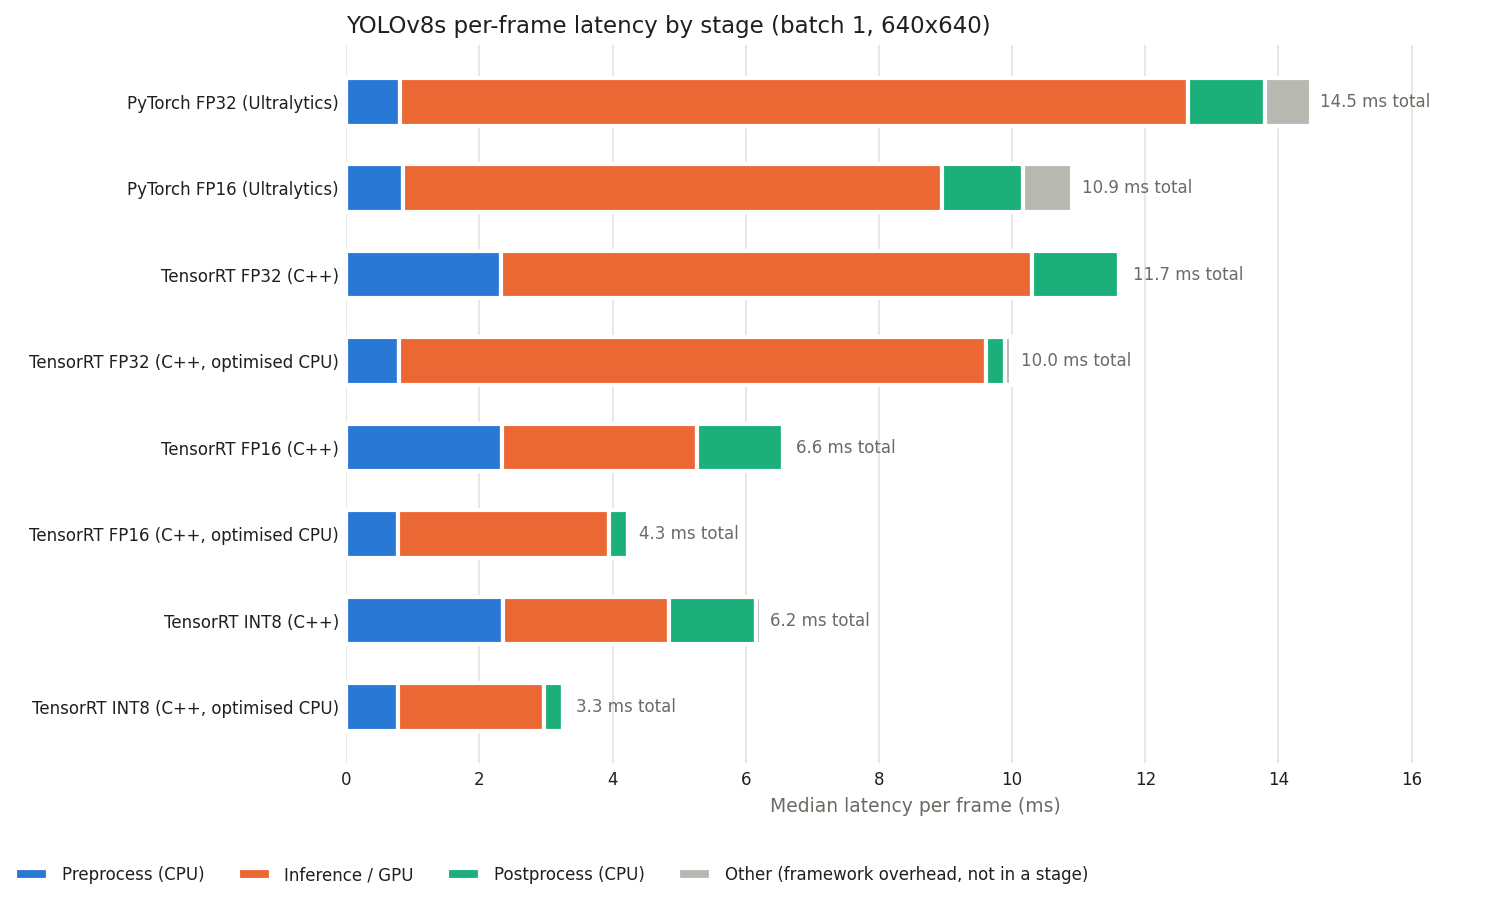

In [25]:
from IPython.display import Markdown, Image, display
sh('python scripts/make_results.py results > /dev/null')
display(Markdown(open(f'{REPO}/results/results.md').read()))
display(Image(filename=f'{REPO}/results/latency.png'))

## Step 11: Demo video / GIF (C++ app, FP16 engine)

$ python scripts/make_demo.py --bin build/yolo_trt --engine engines/yolov8s_fp16.engine --list data/calib.txt --out-dir results
engine engines/yolov8s_fp16.engine: input images [1,3,640,640], output output0 [1,84,8400]
24 frames, pipeline P50 7.60874 ms/frame (131.428 FPS excl. video decode/encode), wall 40.967 FPS incl. I/O
saved results/demo.gif 24 frames


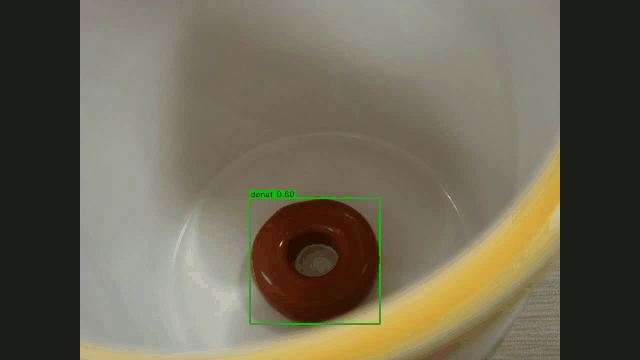

In [26]:
sh('python scripts/make_demo.py --bin build/yolo_trt --engine engines/yolov8s_fp16.engine '
   '--list data/calib.txt --out-dir results')
display(Image(filename=f'{REPO}/results/demo.gif'))

## Step 12: Package everything for GitHub

In [30]:
import zipfile
zpath = '/kaggle/working/yolo-tensorrt-cpp-results.zip'
skip_dirs = {'build', 'engines', 'models', '__pycache__'}
with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(REPO):
        dirs[:] = [d for d in dirs if d not in skip_dirs]
        for fn in files:
            if fn == 'demo_input.mp4':
                continue
            full = os.path.join(root, fn)
            z.write(full, os.path.join('yolo-tensorrt-cpp', os.path.relpath(full, REPO)))
print('saved', zpath, round(os.path.getsize(zpath) / 1e6, 1), 'MB')
print(open(f'{REPO}/results/summary.json').read())

saved /kaggle/working/yolo-tensorrt-cpp-results.zip 4.9 MB
{
  "trt_fp32_vs_pt_map_diff": 0.1,
  "fp16_vs_fp32_map_diff": -0.02,
  "int8_vs_fp32_map_diff": -3.43,
  "speedup_fp32_vs_pt_fp32": 1.45,
  "speedup_fp16_vs_pt_fp32": 3.4,
  "speedup_int8_vs_pt_fp32": 4.38,
  "fp16_baseline_slowest_stage": "GPU (copies + inference)"
}
